# Geographical & Cross-Cutting FAIR Analysis (2011–2025)

> **Research question:** How does data-sharing behaviour vary by **discipline, open-access
> status, MeSH research area, funder** (in combination with discipline/OA), and — the focus of
> this notebook — **country**? Which countries lead or lag in FAIR data sharing, and has the
> gap between them widened or narrowed since 2016?

This notebook originally also rebuilt `01_corpus_overview.ipynb`'s corpus-wide sections,
`08_mandate_compliance.ipynb`'s funder league table, and `06_gender_analysis.ipynb`'s
per-author productivity-trajectory analysis, all as near-duplicate copies. Those were removed
(see §6 for exactly what moved where) — this notebook now covers only what isn't already
covered elsewhere:

| § | Content |
|---|---------|
| 0 | Setup |
| 1 | Discipline stratification: data-sharing score by discipline, DAS category × discipline |
| 2 | Open access vs subscription: data-sharing score and DAS category mix by OA status |
| 3 | MeSH term analysis: top/bottom terms and broad research areas by data-sharing score |
| 4 | Combined interactions: funder × discipline and funder × OA-status heatmaps |
| 5 | **Geographical analysis:** country-level data-sharing score, DAS category mix, restrictive-sharing rate, World Bank income group, international collaboration, and each country's high-data-sharing-score share over time |
| 6 | Key findings and discussion |
| 7 | Exports |

Country is inferred from first-author affiliation text (§5.0). The FAIR principles were
published in **March 2016**; all before/after comparisons use this as the watershed, matching
the other notebooks.

---

In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'pycountry']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


## 0 · Setup

In [2]:
import sqlite3, warnings, importlib
import matplotlib; importlib.reload(matplotlib)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings("ignore")

# Re-run this cell any time to restore all library bindings.
# importlib.reload ensures plt/pd/np are always the real libraries,
# even if earlier cells accidentally overwrote them.
importlib.reload(matplotlib)
plt = matplotlib.pyplot

# ── Style ───────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", font_scale=1.15)
PALETTE   = sns.color_palette("tab10")
FAIR_YEAR = 2016
FIG_W, FIG_H = 13, 5

# ── Database ────────────────────────────────────────────────────────────────
DB_PATH = Path("../data/processed/pmc_fair.db")
assert DB_PATH.exists(), f"Database not found: {DB_PATH}"
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")

con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def qdb(sql, params=()):
    """Run a SQL query → DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

# ── Table detection ─────────────────────────────────────────────────────────
tables = {r[0] for r in con.execute(
    "SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
required = {"article","data_availability","das_category",
            "repo_classification","accession_number","supplementary_material"}
missing  = required - tables
if missing:
    print(f"⚠️  Missing tables (run pipeline stages): {missing}")
else:
    print("✅ All core pipeline tables present")

HAS_FUJI   = "fuji_assessment"    in tables
HAS_MESH   = "article_mesh"       in tables
HAS_DISC   = "article_discipline" in tables
HAS_FUNDER = "article_funder"     in tables
HAS_OA     = "journal_oa"         in tables
HAS_STAGE6 = HAS_DISC and HAS_FUNDER and HAS_OA

# Category order/labels/colours -- shared convention across notebooks (used by
# the discipline heatmap, OA category mix, and country category-mix sections)
CAT_ORDER = [
    "repository_named", "accession_provided", "no_das_but_accession",
    "open_unspecified", "supplementary_only", "no_das_but_supp",
    "available_on_request", "restricted", "no_statement",
]
CAT_LABELS = {
    "repository_named":      "Named repository",
    "accession_provided":    "Accession # in DAS",
    "no_das_but_accession":  "Accession (no DAS)",
    "open_unspecified":      "Open (unspecified)",
    "supplementary_only":    "Supplementary only",
    "no_das_but_supp":       "Supp. (no DAS)",
    "available_on_request":  "Available on request",
    "restricted":            "Restricted",
    "no_statement":          "No statement",
}
CAT_COLOURS = {
    "repository_named":      "#2ca02c",
    "accession_provided":    "#98df8a",
    "no_das_but_accession":  "#b5cf6b",
    "open_unspecified":      "#aec7e8",
    "supplementary_only":    "#ffbb78",
    "no_das_but_supp":       "#ffd8b1",
    "available_on_request":  "#d62728",
    "restricted":            "#ff9896",
    "no_statement":          "#c7c7c7",
}

print(f"   F-UJI (Stage 5)     : {'✅' if HAS_FUJI   else '⚠️  not run'}")
print(f"   Stage 6 enrichment  : {'✅' if HAS_STAGE6 else '⚠️  not run'}")
print(f"     MeSH / discipline : {'✅' if HAS_MESH   else '⚠️ '}")
print(f"     OA status (DOAJ)  : {'✅' if HAS_OA     else '⚠️ '}")
print(f"     Funder extraction : {'✅' if HAS_FUNDER  else '⚠️ '}")

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


✅ All core pipeline tables present
   F-UJI (Stage 5)     : ✅
   Stage 6 enrichment  : ✅
     MeSH / discipline : ✅
     OA status (DOAJ)  : ✅
     Funder extraction : ✅


---
## 1 · Discipline Stratification  *(Stage 6)*

`article_discipline` maps each article to one of 14 research disciplines derived
from MeSH major headings. This section tests whether data-sharing scores differ
systematically across fields and whether all disciplines improved post-2016.

> Uses Stage 6 enrichment data (discipline / funder / OA). Cells skip gracefully if not present in this database.

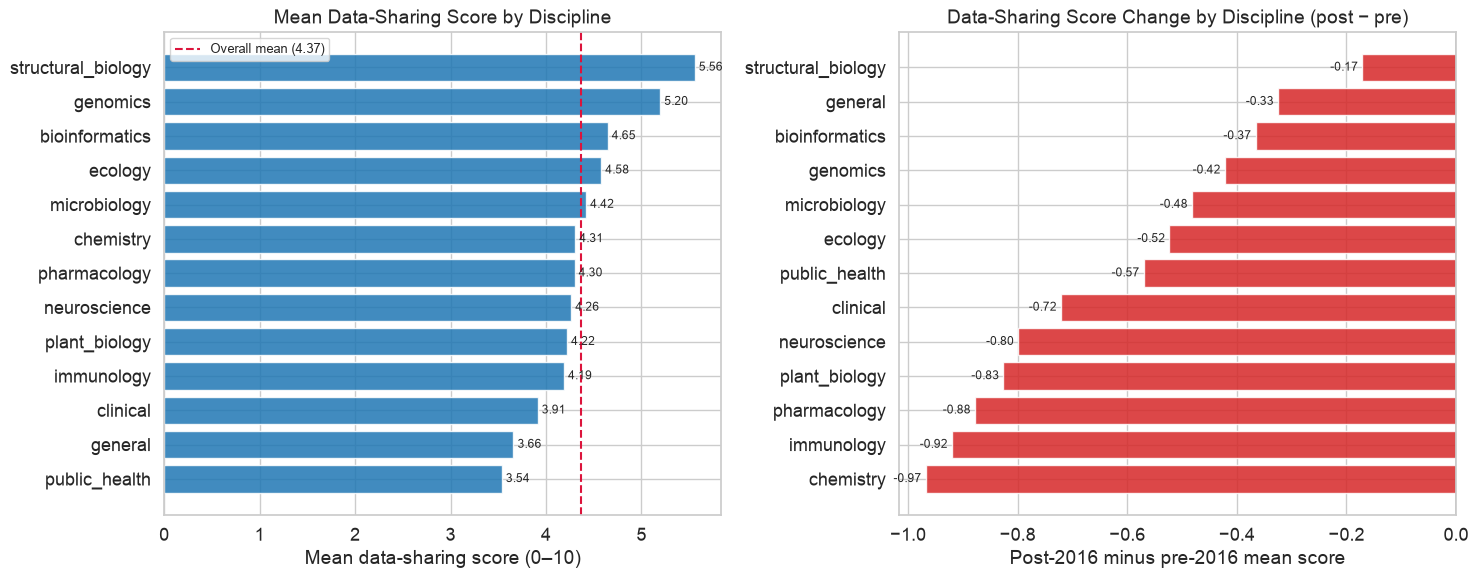

        discipline       n  avg_score  pre_score  post_score  delta
structural_biology   13630      5.558      5.670       5.499 -0.171
          genomics  608274      5.196      5.521       5.099 -0.422
    bioinformatics  131056      4.646      4.946       4.580 -0.366
           ecology  157251      4.578      5.013       4.490 -0.523
      microbiology  328755      4.420      4.831       4.349 -0.482
         chemistry  178242      4.306      5.114       4.146 -0.968
      pharmacology  238780      4.299      5.011       4.133 -0.878
      neuroscience  339474      4.264      4.928       4.129 -0.799
     plant_biology  177081      4.220      4.919       4.093 -0.826
        immunology  212017      4.188      4.964       4.044 -0.920
          clinical 1292431      3.912      4.526       3.805 -0.721
           general 2951952      3.659      3.926       3.601 -0.325
     public_health  245233      3.536      4.036       3.466 -0.570


In [3]:
# ── 1.1  Mean data-sharing score per discipline + pre/post delta ───────────────────
if not HAS_DISC:
    print("⚠️  No discipline data available in this database.")
else:
    df_disc = qdb("""
        SELECT ad.discipline,
               COUNT(*)                                                     AS n,
               ROUND(AVG(dc.data_sharing_score), 3)                                AS avg_score,
               ROUND(AVG(CASE WHEN a.year < 2016
                              THEN dc.data_sharing_score END), 3)                  AS pre_score,
               ROUND(AVG(CASE WHEN a.year > 2016
                              THEN dc.data_sharing_score END), 3)                  AS post_score
        FROM article_discipline ad
        JOIN das_category dc ON dc.article_id = ad.article_id
        JOIN article      a  ON a.article_id  = ad.article_id
        WHERE a.year BETWEEN 2011 AND 2025
        GROUP BY ad.discipline
        ORDER BY avg_score DESC
    """)
    df_disc["delta"] = df_disc["post_score"] - df_disc["pre_score"]

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

    # Left: overall mean data-sharing score per discipline
    ax = axes[0]
    bars = ax.barh(df_disc["discipline"][::-1], df_disc["avg_score"][::-1],
                   color=PALETTE[0], alpha=0.85, edgecolor="white")
    ax.axvline(df_disc["avg_score"].mean(), color="crimson", lw=1.5, ls="--",
               label=f"Overall mean ({df_disc['avg_score'].mean():.2f})")
    ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=8.5)
    ax.set_xlabel("Mean data-sharing score (0–10)")
    ax.set_title("Mean Data-Sharing Score by Discipline")
    ax.legend(fontsize=9)

    # Right: post-2016 minus pre-2016 delta, sorted ascending
    df_disc_s = df_disc.sort_values("delta")
    clrs = ["#2ca02c" if d > 0 else "#d62728" for d in df_disc_s["delta"]]
    ax = axes[1]
    bars2 = ax.barh(df_disc_s["discipline"], df_disc_s["delta"],
                    color=clrs, alpha=0.85, edgecolor="white")
    ax.axvline(0, color="black", lw=1)
    ax.bar_label(bars2, fmt="{:+.2f}", padding=3, fontsize=8.5)
    ax.set_xlabel("Post-2016 minus pre-2016 mean score")
    ax.set_title("Data-Sharing Score Change by Discipline (post − pre)")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_01_discipline_scores.png", **SAVEFIG_KWARGS)
    plt.show()
    print(df_disc[["discipline","n","avg_score","pre_score","post_score","delta"]].to_string(index=False))


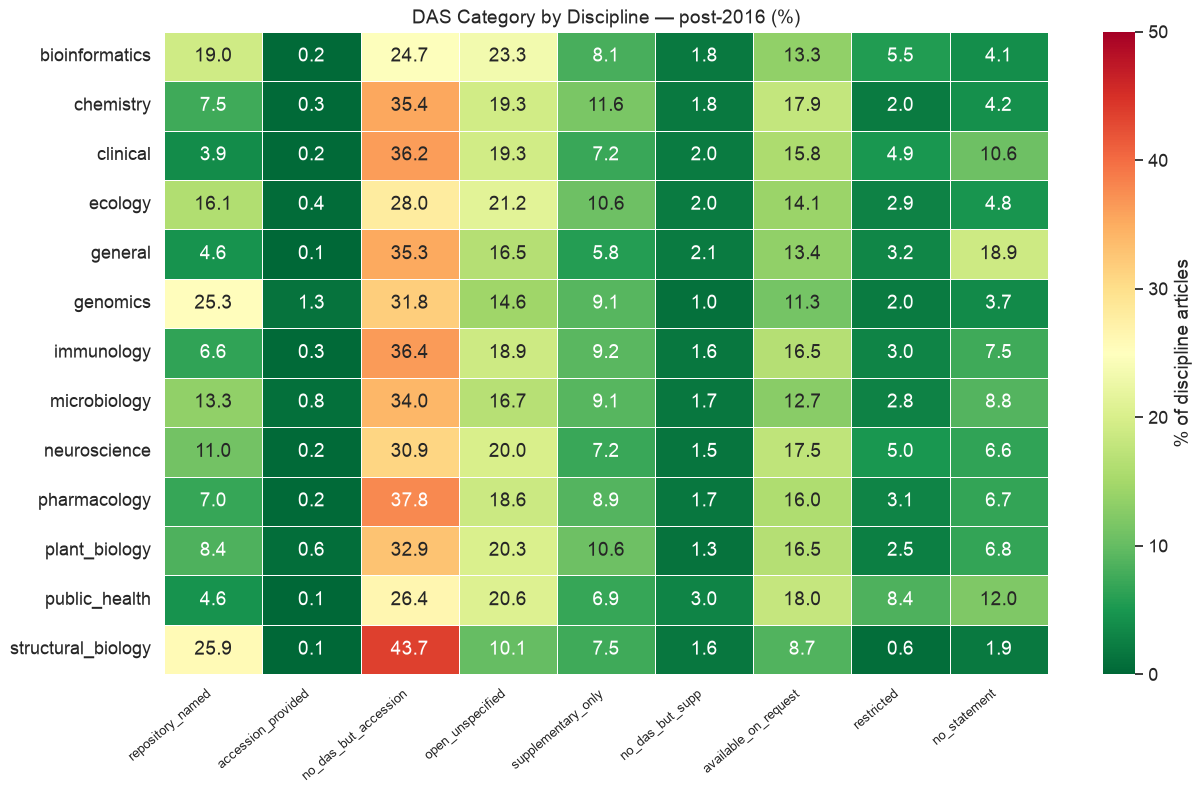

In [4]:
# ── 1.2  DAS category × discipline heatmap (post-2016 only) ─────────────────
if HAS_DISC:
    df_disc_cat = qdb("""
        SELECT ad.discipline, dc.primary_category AS cat, COUNT(*) AS n
        FROM article_discipline ad
        JOIN das_category dc ON dc.article_id = ad.article_id
        JOIN article      a  ON a.article_id  = ad.article_id
        WHERE a.year > 2016
        GROUP BY ad.discipline, dc.primary_category
    """)

    piv_dc = (df_disc_cat
              .pivot_table(index="discipline", columns="cat", values="n", aggfunc="sum")
              .fillna(0))
    present_cats = [c for c in CAT_ORDER if c in piv_dc.columns]
    piv_dc = piv_dc[present_cats]
    piv_dc_pct = piv_dc.div(piv_dc.sum(axis=1), axis=0) * 100

    fig, ax = plt.subplots(figsize=(FIG_W, max(5, len(piv_dc_pct) * 0.55 + 1)))
    sns.heatmap(piv_dc_pct.round(1), annot=True, fmt=".1f", cmap="RdYlGn_r",
                ax=ax, linewidths=0.4, vmin=0, vmax=50,
                cbar_kws={"label": "% of discipline articles"})
    ax.set_title("DAS Category by Discipline — post-2016 (%)")
    ax.set_xlabel(""); ax.set_ylabel("")
    plt.xticks(rotation=40, ha="right", fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_02_discipline_heatmap.png", **SAVEFIG_KWARGS)
    plt.show()


---
## 2 · Open Access vs Subscription Journals  *(Stage 6)*

`journal_oa.oa_status` classifies each journal via the DOAJ API as
`gold_oa`, `hybrid`, `subscription`, or `unknown`.
OA journals tend to adopt data-sharing mandates earlier — this section
tests whether that translates to measurably higher data-sharing scores.

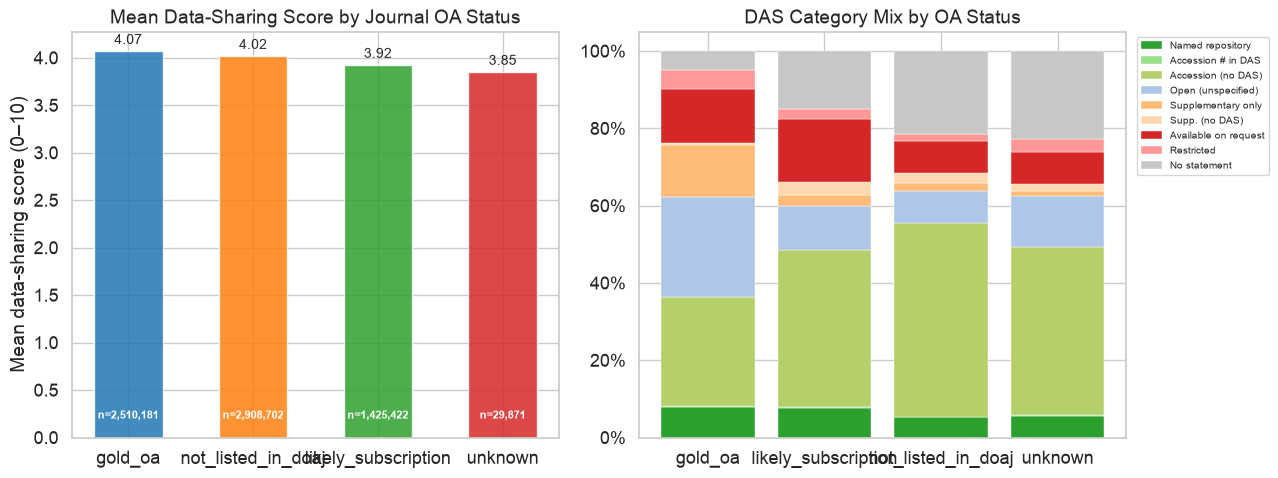

          oa_status       n  avg_score  pre_score  post_score  delta
            gold_oa 2510181      4.071      4.771       3.922 -0.849
 not_listed_in_doaj 2908702      4.019      4.229       3.972 -0.257
likely_subscription 1425422      3.925      4.540       3.803 -0.737
            unknown   29871      3.851      3.709       3.877  0.168


In [5]:
# ── 2.1  Data-sharing score + DAS category mix by OA status ───────────────────────
if not HAS_OA:
    print("⚠️  No OA data available in this database.")
else:
    df_oa = qdb("""
        SELECT jo.oa_status,
               COUNT(*)                                                      AS n,
               ROUND(AVG(dc.data_sharing_score), 3)                                 AS avg_score,
               ROUND(AVG(CASE WHEN a.year < 2016
                              THEN dc.data_sharing_score END), 3)                   AS pre_score,
               ROUND(AVG(CASE WHEN a.year > 2016
                              THEN dc.data_sharing_score END), 3)                   AS post_score
        FROM journal_oa   jo
        JOIN article      a  ON a.journal_id   = jo.journal_id
        JOIN das_category dc ON dc.article_id  = a.article_id
        WHERE a.year BETWEEN 2011 AND 2025
        GROUP BY jo.oa_status
        ORDER BY avg_score DESC
    """)
    df_oa["delta"] = df_oa["post_score"] - df_oa["pre_score"]

    df_oa_cat = qdb("""
        SELECT jo.oa_status, dc.primary_category AS cat, COUNT(*) AS n
        FROM journal_oa   jo
        JOIN article      a  ON a.journal_id   = jo.journal_id
        JOIN das_category dc ON dc.article_id  = a.article_id
        WHERE a.year BETWEEN 2011 AND 2025
        GROUP BY jo.oa_status, dc.primary_category
    """)
    piv_oa = (df_oa_cat
              .pivot_table(index="oa_status", columns="cat", values="n", aggfunc="sum")
              .fillna(0))
    piv_oa = piv_oa.reindex([c for c in CAT_ORDER if c in piv_oa.columns], axis=1)
    piv_oa_pct = piv_oa.div(piv_oa.sum(axis=1), axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

    # Left: mean data-sharing score bar
    ax = axes[0]
    bars = ax.bar(df_oa["oa_status"].astype(str), df_oa["avg_score"],
                  color=PALETTE[:len(df_oa)], alpha=0.85, edgecolor="white", width=0.55)
    ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=10)
    ax.set_ylabel("Mean data-sharing score (0–10)")
    ax.set_title("Mean Data-Sharing Score by Journal OA Status")
    for i, row in df_oa.reset_index().iterrows():
        ax.text(i, 0.2, f"n={int(row['n']):,}", ha="center",
                fontsize=8, color="white", fontweight="bold")

    # Right: DAS category composition
    ax = axes[1]
    bot = np.zeros(len(piv_oa_pct))
    for cat in piv_oa_pct.columns:
        ax.bar(piv_oa_pct.index.astype(str), piv_oa_pct[cat], bottom=bot,
               color=CAT_COLOURS.get(cat, "#aaa"), edgecolor="white", lw=0.3,
               label=CAT_LABELS.get(cat, cat))
        bot += piv_oa_pct[cat].values
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title("DAS Category Mix by OA Status")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7.5)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_03_oa_scores.png", **SAVEFIG_KWARGS)
    plt.show()
    print(df_oa[["oa_status","n","avg_score","pre_score","post_score","delta"]].to_string(index=False))


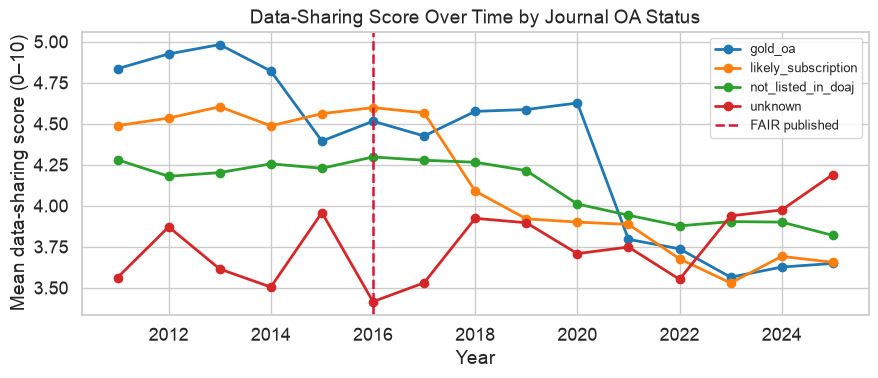

In [6]:
# ── 2.2  OA score trend over time ──────────────────────────────────────────
if HAS_OA:
    df_oa_yr = qdb("""
        SELECT jo.oa_status, a.year AS year,
               ROUND(AVG(dc.data_sharing_score), 3) AS avg_score, COUNT(*) AS n
        FROM journal_oa   jo
        JOIN article      a  ON a.journal_id   = jo.journal_id
        JOIN das_category dc ON dc.article_id  = a.article_id
        WHERE a.year BETWEEN 2011 AND 2025
        GROUP BY jo.oa_status, a.year
        HAVING n >= 20
        ORDER BY a.year
    """)

    fig, ax = plt.subplots(figsize=(9, 4))
    for i, (oa, grp) in enumerate(df_oa_yr.groupby("oa_status")):
        ax.plot(grp["year"], grp["avg_score"], lw=2, marker="o",
                color=PALETTE[i], label=oa)
    ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
    ax.set_xlabel("Year"); ax.set_ylabel("Mean data-sharing score (0–10)")
    ax.set_title("Data-Sharing Score Over Time by Journal OA Status")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_04_oa_trend.png", **SAVEFIG_KWARGS)
    plt.show()


---
## 3 · MeSH Term Analysis  *(Stage 6)*

`article_mesh` stores all MeSH headings per article with a `mesh_major` flag
(1 = major topic). This section identifies which biomedical topics are leading
or lagging in data-sharing adoption, and tracks how topical composition shifts across
the FAIR boundary using the `mesh_broad` discipline buckets.

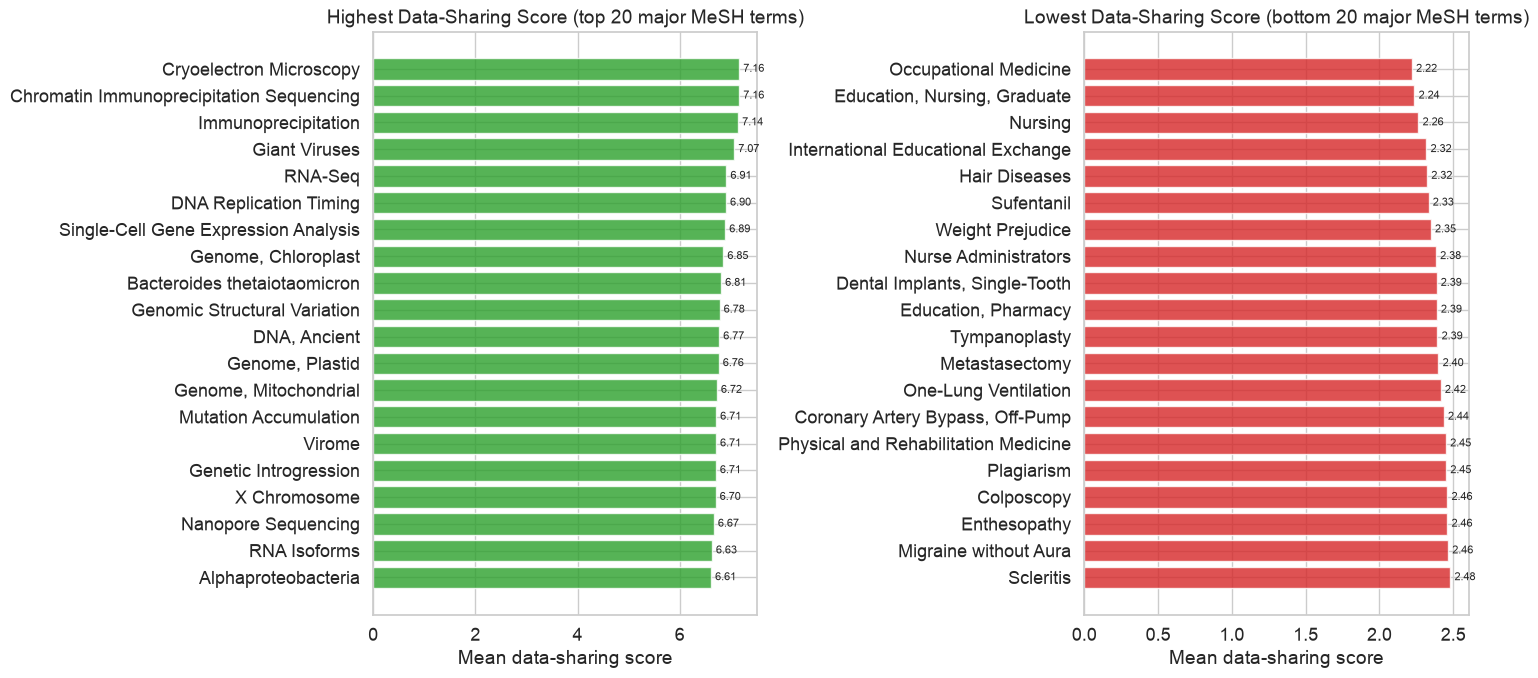

In [7]:
# ── 3.1  Top/bottom MeSH terms by mean data-sharing score ──────────────────────────
if not HAS_MESH:
    print("⚠️  No MeSH data available in this database.")
else:
    df_mesh_top = qdb("""
        SELECT am.mesh_term,
               COUNT(DISTINCT am.article_id) AS n_articles,
               ROUND(AVG(dc.data_sharing_score), 3)  AS avg_score
        FROM article_mesh am
        JOIN das_category dc ON dc.article_id = am.article_id
        JOIN article      a  ON a.article_id  = am.article_id
        WHERE am.mesh_major = 1
          AND a.year BETWEEN 2011 AND 2025
        GROUP BY am.mesh_term
        HAVING n_articles >= 50
        ORDER BY avg_score DESC LIMIT 20
    """)
    df_mesh_bot = qdb("""
        SELECT am.mesh_term,
               COUNT(DISTINCT am.article_id) AS n_articles,
               ROUND(AVG(dc.data_sharing_score), 3)  AS avg_score
        FROM article_mesh am
        JOIN das_category dc ON dc.article_id = am.article_id
        JOIN article      a  ON a.article_id  = am.article_id
        WHERE am.mesh_major = 1
          AND a.year BETWEEN 2011 AND 2025
        GROUP BY am.mesh_term
        HAVING n_articles >= 50
        ORDER BY avg_score ASC LIMIT 20
    """)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 2))
    for ax, df, title, clr in [
        (axes[0], df_mesh_top, "Highest Data-Sharing Score (top 20 major MeSH terms)", "#2ca02c"),
        (axes[1], df_mesh_bot, "Lowest Data-Sharing Score (bottom 20 major MeSH terms)", "#d62728"),
    ]:
        bars = ax.barh(df["mesh_term"][::-1], df["avg_score"][::-1],
                       color=clr, alpha=0.8, edgecolor="white")
        ax.bar_label(bars, fmt="{:.2f}", padding=3, fontsize=8)
        ax.set_xlabel("Mean data-sharing score"); ax.set_title(title)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_05_mesh_scores.png", **SAVEFIG_KWARGS)
    plt.show()


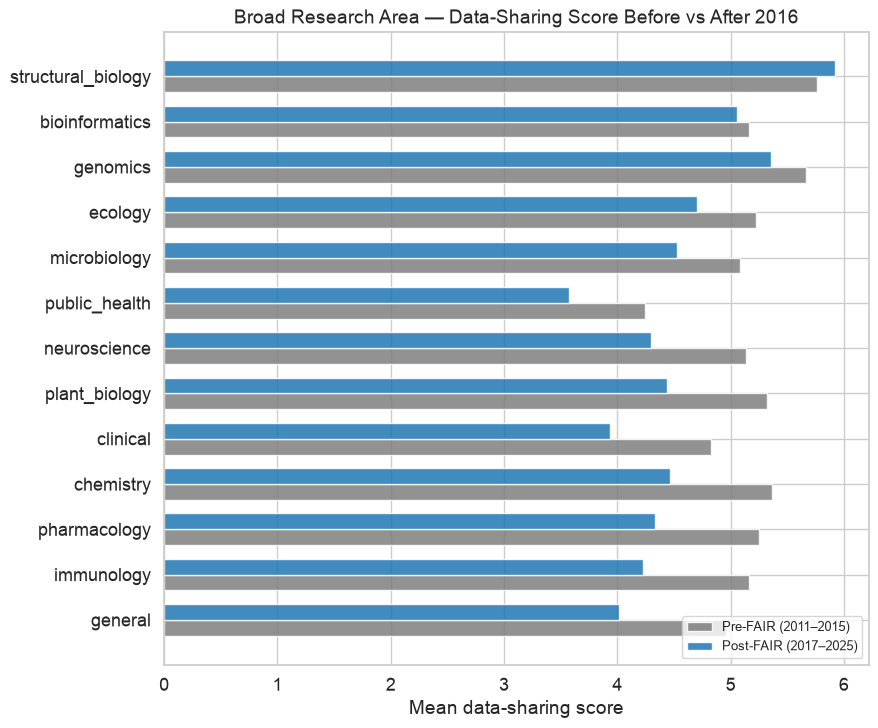

period              pre_FAIR  post_FAIR  delta
broad                                         
general                4.963      4.015 -0.948
immunology             5.162      4.230 -0.932
pharmacology           5.253      4.333 -0.920
chemistry              5.364      4.464 -0.900
clinical               4.828      3.933 -0.895
plant_biology          5.317      4.439 -0.878
neuroscience           5.132      4.293 -0.839
public_health          4.244      3.573 -0.671
microbiology           5.083      4.527 -0.556
ecology                5.227      4.705 -0.522
genomics               5.662      5.356 -0.306
bioinformatics         5.163      5.052 -0.111
structural_biology     5.759      5.922  0.163


In [8]:
# ── 3.2  Broad research area: pre vs post FAIR comparison ──────────────────
if HAS_MESH:
    df_broad = qdb("""
        SELECT am.mesh_broad AS broad,
               CASE WHEN a.year < 2016 THEN 'pre_FAIR'
                    WHEN a.year > 2016 THEN 'post_FAIR'
                    ELSE 'transition' END                    AS period,
               COUNT(DISTINCT am.article_id)                AS n,
               ROUND(AVG(dc.data_sharing_score), 3)                 AS avg_score
        FROM article_mesh am
        JOIN das_category dc ON dc.article_id = am.article_id
        JOIN article      a  ON a.article_id  = am.article_id
        WHERE am.mesh_broad IS NOT NULL
          AND a.year BETWEEN 2011 AND 2025
          AND a.year != 2016
        GROUP BY am.mesh_broad, period
    """)

    piv_broad = (df_broad.pivot_table(
                     index="broad", columns="period",
                     values="avg_score", aggfunc="mean")
                 .fillna(0))
    cols_ord = [c for c in ["pre_FAIR","post_FAIR"] if c in piv_broad.columns]
    piv_broad = piv_broad[cols_ord]
    if len(cols_ord) == 2:
        piv_broad["delta"] = piv_broad["post_FAIR"] - piv_broad["pre_FAIR"]
        piv_broad = piv_broad.sort_values("delta", ascending=True)

    fig, ax = plt.subplots(figsize=(9, max(4, len(piv_broad) * 0.5 + 1)))
    x = np.arange(len(piv_broad))
    w = 0.35
    ax.barh(x - w/2, piv_broad.get("pre_FAIR",  pd.Series(0, index=piv_broad.index)), w,
            color=PALETTE[7], alpha=0.85, label="Pre-FAIR (2011–2015)", edgecolor="white")
    ax.barh(x + w/2, piv_broad.get("post_FAIR", pd.Series(0, index=piv_broad.index)), w,
            color=PALETTE[0], alpha=0.85, label="Post-FAIR (2017–2025)", edgecolor="white")
    ax.set_yticks(x); ax.set_yticklabels(piv_broad.index)
    ax.set_xlabel("Mean data-sharing score")
    ax.set_title("Broad Research Area — Data-Sharing Score Before vs After 2016")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_06_mesh_broad.png", **SAVEFIG_KWARGS)
    plt.show()
    print(piv_broad.round(3).to_string())


---
## 4 · Combined Interactions: Funder × Discipline × OA  *(Stage 6)*

The most policy-relevant question: which **combination** of funder, discipline,
and OA status produces the best data-sharing outcomes?
These three-way analyses only become possible once Stage 6 enrichment is run.

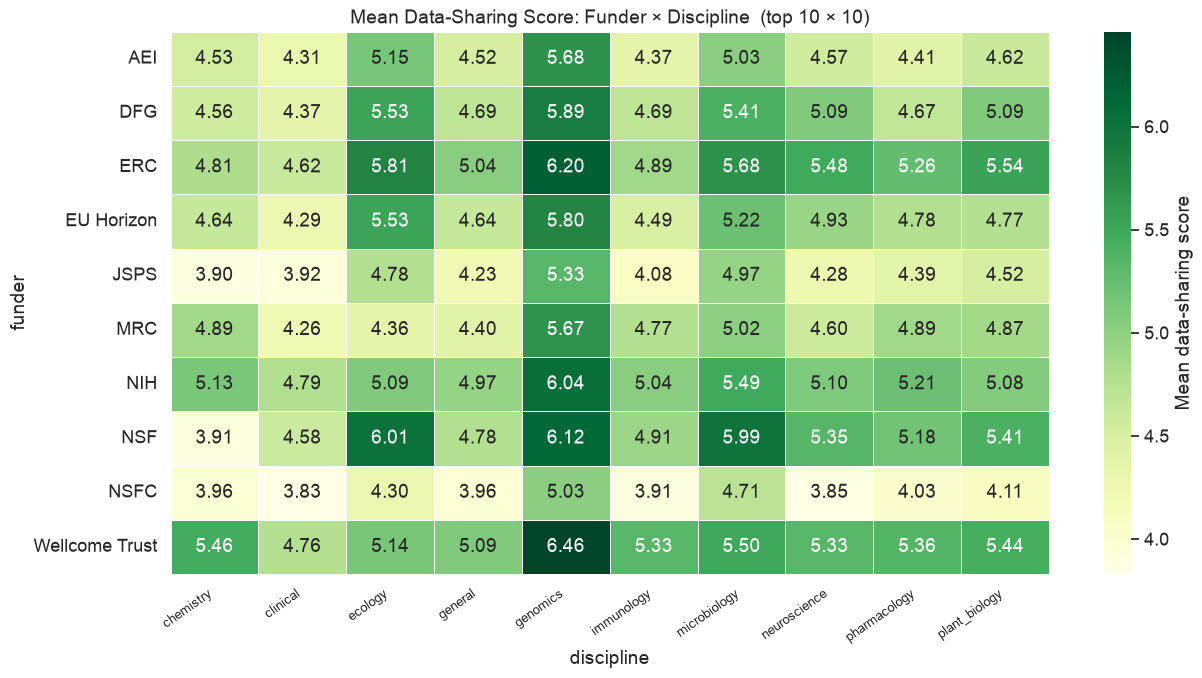

In [9]:
# ── 4.1  Funder × discipline data-sharing score heatmap ────────────────────────────
if not (HAS_FUNDER and HAS_DISC):
    print("⚠️  Requires both funder and discipline data (Stage 6).")
else:
    df_fd = qdb("""
        SELECT af.funder_norm AS funder, ad.discipline,
               COUNT(DISTINCT af.article_id)   AS n,
               ROUND(AVG(dc.data_sharing_score), 2)    AS avg_score
        FROM article_funder     af
        JOIN article_discipline ad ON ad.article_id = af.article_id
        JOIN das_category       dc ON dc.article_id = af.article_id
        WHERE af.funder_norm != 'none'
        GROUP BY af.funder_norm, ad.discipline
        HAVING n >= 10
    """)

    top_f_fd = df_fd.groupby("funder")["n"].sum().nlargest(10).index
    top_d_fd = df_fd.groupby("discipline")["n"].sum().nlargest(10).index
    piv_fd = (df_fd[df_fd["funder"].isin(top_f_fd) & df_fd["discipline"].isin(top_d_fd)]
              .pivot_table(index="funder", columns="discipline",
                           values="avg_score", aggfunc="mean"))

    fig, ax = plt.subplots(figsize=(FIG_W, max(4, len(piv_fd) * 0.6 + 1)))
    sns.heatmap(piv_fd.astype(float), annot=True, fmt=".2f", cmap="YlGn",
                ax=ax, linewidths=0.4, cbar_kws={"label": "Mean data-sharing score"},
                mask=piv_fd.isna())
    ax.set_title("Mean Data-Sharing Score: Funder × Discipline  (top 10 × 10)")
    plt.xticks(rotation=35, ha="right", fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_07_funder_discipline.png", **SAVEFIG_KWARGS)
    plt.show()


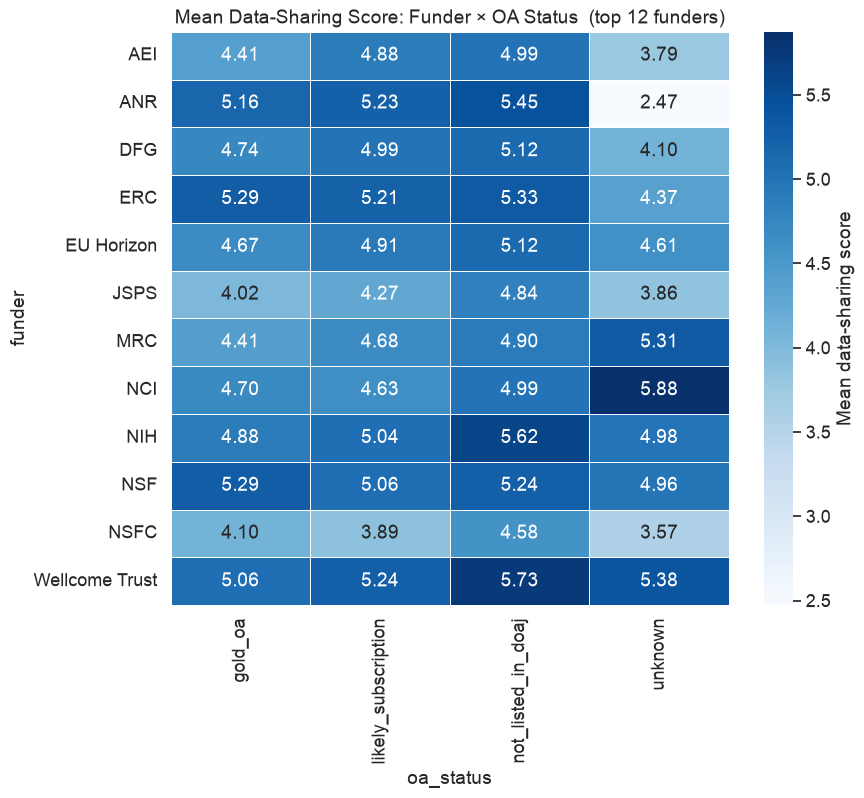

In [10]:
# ── 4.2  Funder × OA status data-sharing score heatmap ─────────────────────────────
if not (HAS_FUNDER and HAS_OA):
    print("⚠️  Requires funder and OA status data (Stage 6).")
else:
    df_foa = qdb("""
        SELECT af.funder_norm AS funder, jo.oa_status,
               COUNT(DISTINCT af.article_id)   AS n,
               ROUND(AVG(dc.data_sharing_score), 3)    AS avg_score
        FROM article_funder af
        JOIN das_category   dc ON dc.article_id = af.article_id
        JOIN article        a  ON a.article_id  = af.article_id
        JOIN journal_oa     jo ON jo.journal_id  = a.journal_id
        WHERE af.funder_norm != 'none'
        GROUP BY af.funder_norm, jo.oa_status
        HAVING n >= 10
    """)

    top_f_foa = df_foa.groupby("funder")["n"].sum().nlargest(12).index
    piv_foa = (df_foa[df_foa["funder"].isin(top_f_foa)]
               .pivot_table(index="funder", columns="oa_status",
                            values="avg_score", aggfunc="mean"))

    fig, ax = plt.subplots(figsize=(9, max(4, len(piv_foa) * 0.6 + 1)))
    sns.heatmap(piv_foa.astype(float), annot=True, fmt=".2f", cmap="Blues",
                ax=ax, linewidths=0.4, cbar_kws={"label": "Mean data-sharing score"},
                mask=piv_foa.isna())
    ax.set_title("Mean Data-Sharing Score: Funder × OA Status  (top 12 funders)")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_08_funder_oa.png", **SAVEFIG_KWARGS)
    plt.show()


---
## 5 · Geographical Analysis — Country-Level Data-Sharing Adoption

Affiliation strings from PubMed are parsed to extract the **first author's
country** for each article. This section answers:

- Which countries produce the most data-sharing articles?
- Which countries show the biggest data-sharing score improvement post-2016?
- Are high-income, mandate-heavy countries (US, UK, DE) ahead of lower-income ones?
- Which countries still have high "available on request" rates?

Country extraction uses a regex scan of the last comma-delimited segment of
each affiliation string — the standard position of country in PubMed records.


In [11]:
# ── 5.0  Build country lookup and extract country per article ────────────────
import re, pycountry

# Build name → ISO-2 lookup from pycountry + common PubMed aliases
_lookup_raw = {}
for _c in pycountry.countries:
    for _n in [_c.name,
               getattr(_c, "official_name", None),
               getattr(_c, "common_name",   None)]:
        if _n:
            _lookup_raw[_n.lower()] = _c.alpha_2

COUNTRY_ALIASES = {
    "usa": "US", "u.s.a": "US", "u.s.a.": "US", "united states": "US",
    "united states of america": "US",
    "uk": "GB", "u.k.": "GB", "england": "GB", "scotland": "GB",
    "wales": "GB", "great britain": "GB", "united kingdom": "GB",
    "south korea": "KR", "republic of korea": "KR",
    "taiwan": "TW", "republic of china": "TW",
    "russia": "RU", "russian federation": "RU",
    "iran": "IR", "islamic republic of iran": "IR",
    "vietnam": "VN", "viet nam": "VN",
    "czech republic": "CZ", "czechia": "CZ",
    "peoples republic of china": "CN", "p.r. china": "CN",
    "p.r.china": "CN", "china mainland": "CN",
    "hong kong": "HK", "the netherlands": "NL", "holland": "NL",
    "uae": "AE", "united arab emirates": "AE",
    "ivory coast": "CI", "cote d'ivoire": "CI",
    "tanzania": "TZ", "laos": "LA", "moldova": "MD",
    "bolivia": "BO", "venezuela": "VE", "syria": "SY",
    "trinidad": "TT", "trinidad and tobago": "TT",
}
_lookup_raw.update({k: v for k, v in COUNTRY_ALIASES.items()})

# ISO-2 → display name for charts
ISO2_NAME = {c.alpha_2: c.name for c in pycountry.countries}
ISO2_NAME.update({"US": "United States", "GB": "United Kingdom",
                  "KR": "South Korea",   "TW": "Taiwan",
                  "RU": "Russia",        "IR": "Iran",
                  "VN": "Vietnam",       "CZ": "Czechia",
                  "CN": "China",         "HK": "Hong Kong"})

# Sort by length descending so longer names match before substrings
_SORTED_NAMES = sorted(_lookup_raw.keys(), key=len, reverse=True)

# Single compiled alternation regex, built once, instead of looping over
# ~250 names with a separate re.search() call each -- that loop, run against
# 5.4M affiliation rows, is what timed out. findall() + max(key=len) preserves
# the original "prefer the longest matching name found anywhere in the text"
# tie-breaking behaviour exactly, just in one regex pass instead of ~250.
_ALIAS_RE = re.compile(r"\b(" + "|".join(re.escape(n) for n in _SORTED_NAMES) + r")\b")

def _country_from_affil(text):
    """Extract ISO-2 country code from a PubMed affiliation string."""
    t = text.lower().rstrip(". \n")
    parts = [p.strip() for p in t.split(",")]
    for part in reversed(parts[-3:]):
        part_clean = re.sub(r"\d{4,}", "", part).strip()
        if part_clean in _lookup_raw:
            return _lookup_raw[part_clean]
    matches = _ALIAS_RE.findall(t)
    if matches:
        return _lookup_raw[max(matches, key=len)]
    return None

# ── Pull first-author affiliations from DB ───────────────────────────────────
df_aff_raw = qdb("""
    SELECT
        a.article_id,
        a.year          AS year,
        dc.data_sharing_score,
        dc.primary_category              AS cat,
        af_tbl.affiliation               AS aff_text
    FROM article           a
    JOIN das_category      dc   ON dc.article_id   = a.article_id
    JOIN article_author    aa   ON aa.article_id   = a.article_id
                                AND aa.author_position = 1
    JOIN author_affiliation aaf ON aaf.article_id  = a.article_id
                                AND aaf.author_id   = aa.author_id
    JOIN affiliation        af_tbl ON af_tbl.affiliation_id = aaf.affiliation_id
    WHERE a.year BETWEEN 2011 AND 2025
    ORDER BY a.article_id, aaf.affiliation_id
""")

# One row per article (keep first affiliation)
df_aff_raw = df_aff_raw.drop_duplicates(subset="article_id", keep="first").copy()

# Extract country
df_aff_raw["iso2"] = df_aff_raw["aff_text"].apply(_country_from_affil)
df_geo = df_aff_raw[df_aff_raw["iso2"].notna()].copy()
df_geo["country"] = df_geo["iso2"].map(ISO2_NAME).fillna(df_geo["iso2"])
df_geo["period"]  = df_geo["year"].apply(
    lambda y: "pre_FAIR" if y < 2016 else ("FAIR_year" if y == 2016 else "post_FAIR"))

n_total    = len(df_aff_raw)
n_resolved = len(df_geo)
print(f"Articles with first-author affiliation : {n_total:,}")
print(f"Country successfully resolved          : {n_resolved:,}  ({n_resolved/n_total*100:.1f}%)")
print(f"Unique countries identified            : {df_geo['iso2'].nunique()}")
print(f"\nTop 10 countries by article count:")
print(df_geo["country"].value_counts().head(10).to_string())


Articles with first-author affiliation : 4,288,815
Country successfully resolved          : 3,494,483  (81.5%)
Unique countries identified            : 219

Top 10 countries by article count:
country
China             708343
United States     536976
United Kingdom    224784
Germany           172595
Japan             156432
India             156155
Italy             110049
Taiwan            108041
Canada             92083
Australia          86232


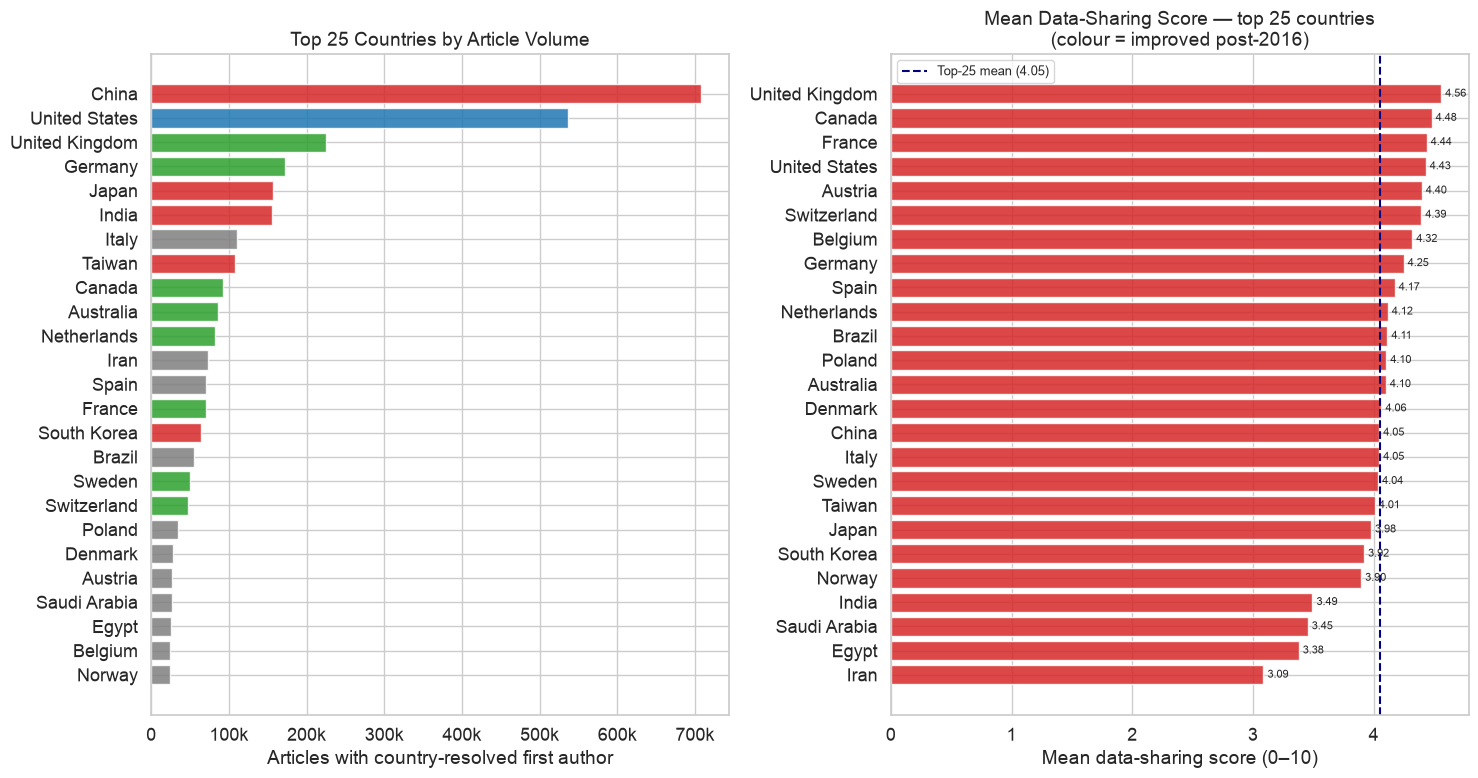

       country  n_total  avg_score  pre_score  post_score  delta
         China   708343      4.046      5.092       3.941 -1.151
 United States   536976      4.431      5.111       4.275 -0.836
United Kingdom   224784      4.559      5.432       4.375 -1.057
       Germany   172595      4.248      5.090       4.100 -0.989
         Japan   156432      3.977      4.745       3.830 -0.915
         India   156155      3.492      3.550       3.470 -0.081
         Italy   110049      4.046      4.730       3.911 -0.819
        Taiwan   108041      4.009      5.420       3.791 -1.629
        Canada    92083      4.480      5.560       4.264 -1.296
     Australia    86232      4.101      4.934       3.948 -0.986
   Netherlands    81913      4.117      4.810       3.997 -0.813
          Iran    73225      3.086      3.485       3.013 -0.472
         Spain    70755      4.174      5.041       4.013 -1.028
        France    70190      4.439      5.167       4.251 -0.916
   South Korea    64193  

In [12]:
# ── 5.1  Article volume and mean data-sharing score by country (top 25) ─────────────
country_stats = (df_geo.groupby(["iso2", "country"])
                 .agg(
                     n_total   = ("article_id", "count"),
                     avg_score = ("data_sharing_score",  "mean"),
                     pre_score = ("data_sharing_score",
                                  lambda x: x[df_geo.loc[x.index, "year"] < 2016].mean()),
                     post_score= ("data_sharing_score",
                                  lambda x: x[df_geo.loc[x.index, "year"] > 2016].mean()),
                 )
                 .reset_index())
country_stats["delta"] = country_stats["post_score"] - country_stats["pre_score"]
country_stats = country_stats.sort_values("n_total", ascending=False)

top25 = country_stats.head(25).copy()

# Continent lookup for the top-25 colour grouping below (pycountry has no
# continent field, so this is an explicit ISO2 -> continent map; extend it
# if a future re-run's top-25 membership changes). Replaces the old ad hoc
# 8/6-country clusters, whose inconsistency -- e.g. grouping Germany/
# Canada/UK together but leaving Denmark/Poland/Belgium grey even though
# they too are top-25 by volume -- is what Daniel flagged; continent is a
# well-defined partition that covers all 25 instead.
import matplotlib.patches as mpatches

ISO2_CONTINENT = {
    "US": "North America", "CA": "North America",
    "BR": "South America",
    "GB": "Europe", "DE": "Europe", "IT": "Europe", "NL": "Europe",
    "ES": "Europe", "FR": "Europe", "SE": "Europe", "CH": "Europe",
    "PL": "Europe", "DK": "Europe", "AT": "Europe", "BE": "Europe", "NO": "Europe",
    "CN": "Asia", "JP": "Asia", "IN": "Asia", "TW": "Asia", "KR": "Asia",
    "IR": "Asia", "SA": "Asia",
    "EG": "Africa",
    "AU": "Oceania",
}
top25["continent"] = top25["iso2"].map(ISO2_CONTINENT).fillna("Other")

CONT_ORDER  = ["North America", "South America", "Europe", "Asia", "Africa", "Oceania", "Other"]
CONT_COLOUR = {c: PALETTE[i] for i, c in enumerate(CONT_ORDER)}

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 3))

# Left: article count, coloured by continent (legend below)
ax = axes[0]
colours_vol = [CONT_COLOUR[c] for c in top25["continent"]]
bars = ax.barh(top25["country"][::-1], top25["n_total"][::-1],
               color=colours_vol[::-1], alpha=0.85, edgecolor="white")
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x,_: f"{int(x/1e3)}k" if x >= 1000 else str(int(x))))
ax.set_xlabel("Articles with country-resolved first author")
ax.set_title("Top 25 Countries by Article Volume")
_present = [c for c in CONT_ORDER if c in set(top25["continent"])]
ax.legend(handles=[mpatches.Patch(color=CONT_COLOUR[c], label=c) for c in _present],
          fontsize=8.5, loc="lower right", title="Continent", title_fontsize=9)

# Right: mean data-sharing score (same top-25, sorted by score)
top25_s = top25.sort_values("avg_score", ascending=True)
clrs_s  = ["#2ca02c" if d > 0 else "#d62728"
           for d in top25_s["delta"].fillna(0)]
bars2 = axes[1].barh(top25_s["country"], top25_s["avg_score"],
                     color=clrs_s, alpha=0.85, edgecolor="white")
axes[1].bar_label(bars2, fmt="{:.2f}", padding=3, fontsize=8)
axes[1].axvline(top25_s["avg_score"].mean(), color="navy", lw=1.5, ls="--",
                label=f"Top-25 mean ({top25_s['avg_score'].mean():.2f})")
axes[1].set_xlabel("Mean data-sharing score (0–10)")
axes[1].set_title("Mean Data-Sharing Score — top 25 countries\n(colour = improved post-2016)")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_09_country_volume_score.png", **SAVEFIG_KWARGS)
plt.show()
print(top25[["country","n_total","avg_score","pre_score","post_score","delta"]]
      .round(3).to_string(index=False))


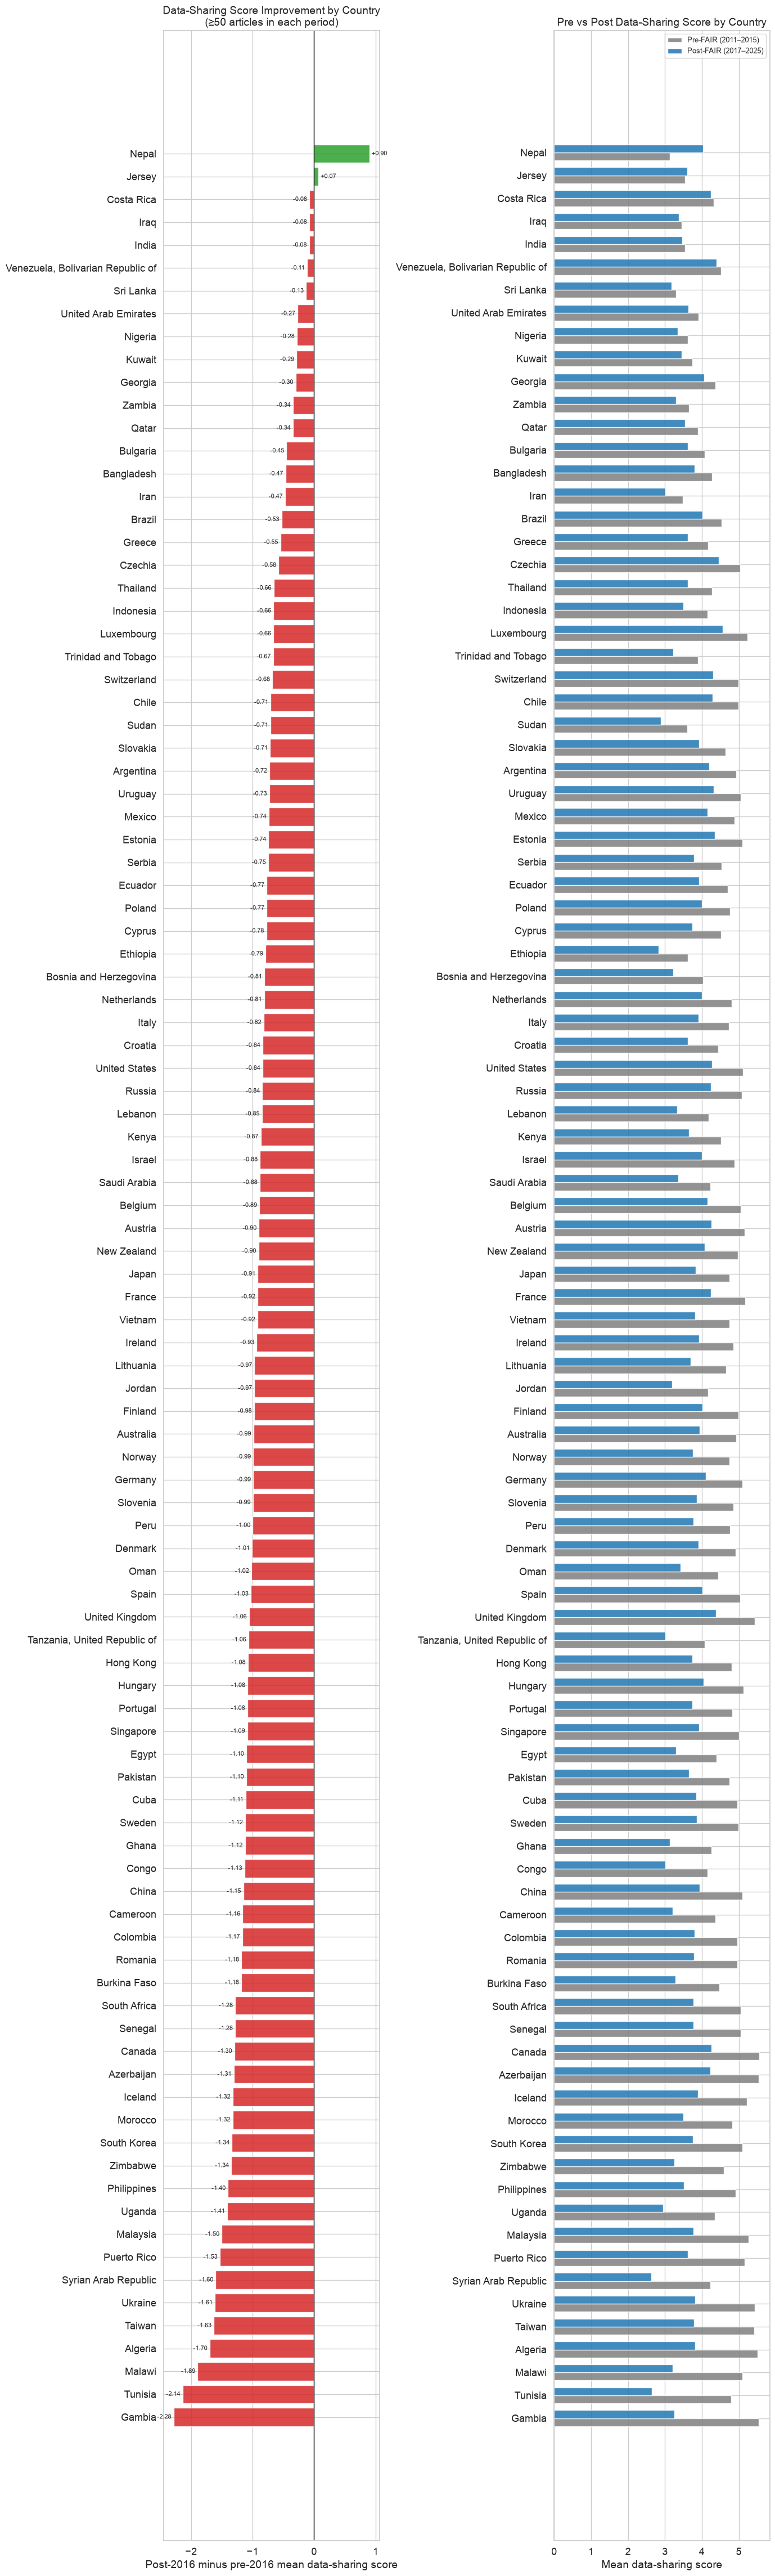

                          country  pre_FAIR  post_FAIR  delta
                           Gambia     5.542      3.259 -2.283
                          Tunisia     4.787      2.650 -2.137
                           Malawi     5.100      3.207 -1.893
                          Algeria     5.513      3.816 -1.697
                           Taiwan     5.420      3.791 -1.629
                          Ukraine     5.431      3.819 -1.613
             Syrian Arab Republic     4.231      2.631 -1.599
                      Puerto Rico     5.157      3.625 -1.532
                         Malaysia     5.268      3.768 -1.501
                           Uganda     4.357      2.947 -1.410
                      Philippines     4.917      3.518 -1.399
                         Zimbabwe     4.593      3.248 -1.344
                      South Korea     5.098      3.763 -1.335
                          Morocco     4.819      3.495 -1.325
                          Iceland     5.222      3.899 -1.323
        

In [13]:
# ── 5.2  Pre vs post data-sharing score change by country (min 50 articles each) ────
country_period = (df_geo[df_geo["year"] != 2016]
                  .groupby(["iso2","country","period"])
                  .agg(n=("article_id","count"), avg=("data_sharing_score","mean"))
                  .reset_index())

piv_cp = (country_period
          .pivot_table(index=["iso2","country"], columns="period",
                       values="avg", aggfunc="mean")
          .reset_index())
piv_cp.columns.name = None

# Only keep countries with ≥50 articles in each period
n_piv = (country_period
         .pivot_table(index=["iso2","country"], columns="period",
                      values="n", aggfunc="sum")
         .reset_index())
n_piv.columns.name = None

mask = ((n_piv.get("pre_FAIR",  pd.Series(0, index=n_piv.index)) >= 50) &
        (n_piv.get("post_FAIR", pd.Series(0, index=n_piv.index)) >= 50))
piv_cp = piv_cp[mask.values].copy()

if "pre_FAIR" in piv_cp.columns and "post_FAIR" in piv_cp.columns:
    piv_cp["delta"] = piv_cp["post_FAIR"] - piv_cp["pre_FAIR"]
    piv_cp = piv_cp.sort_values("delta")

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 1, max(6, len(piv_cp) * 0.45 + 1)))

    # Left: delta bar
    ax = axes[0]
    clrs_d = ["#2ca02c" if d > 0 else "#d62728" for d in piv_cp["delta"]]
    bars_d = ax.barh(piv_cp["country"], piv_cp["delta"],
                     color=clrs_d, alpha=0.85, edgecolor="white")
    ax.bar_label(bars_d, fmt="{:+.2f}", padding=3, fontsize=8)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Post-2016 minus pre-2016 mean data-sharing score")
    ax.set_title("Data-Sharing Score Improvement by Country\n(≥50 articles in each period)")

    # Right: grouped bar pre vs post
    ax = axes[1]
    y = np.arange(len(piv_cp))
    w = 0.35
    ax.barh(y - w/2, piv_cp["pre_FAIR"],  w, color=PALETTE[7], alpha=0.85,
            label="Pre-FAIR (2011–2015)", edgecolor="white")
    ax.barh(y + w/2, piv_cp["post_FAIR"], w, color=PALETTE[0], alpha=0.85,
            label="Post-FAIR (2017–2025)", edgecolor="white")
    ax.set_yticks(y); ax.set_yticklabels(piv_cp["country"])
    ax.set_xlabel("Mean data-sharing score"); ax.legend(fontsize=9)
    ax.set_title("Pre vs Post Data-Sharing Score by Country")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_10_country_delta.png", **SAVEFIG_KWARGS)
    plt.show()
    print(piv_cp[["country","pre_FAIR","post_FAIR","delta"]].round(3).to_string(index=False))
else:
    print("⚠️  Not enough pre/post data to compute country deltas.")


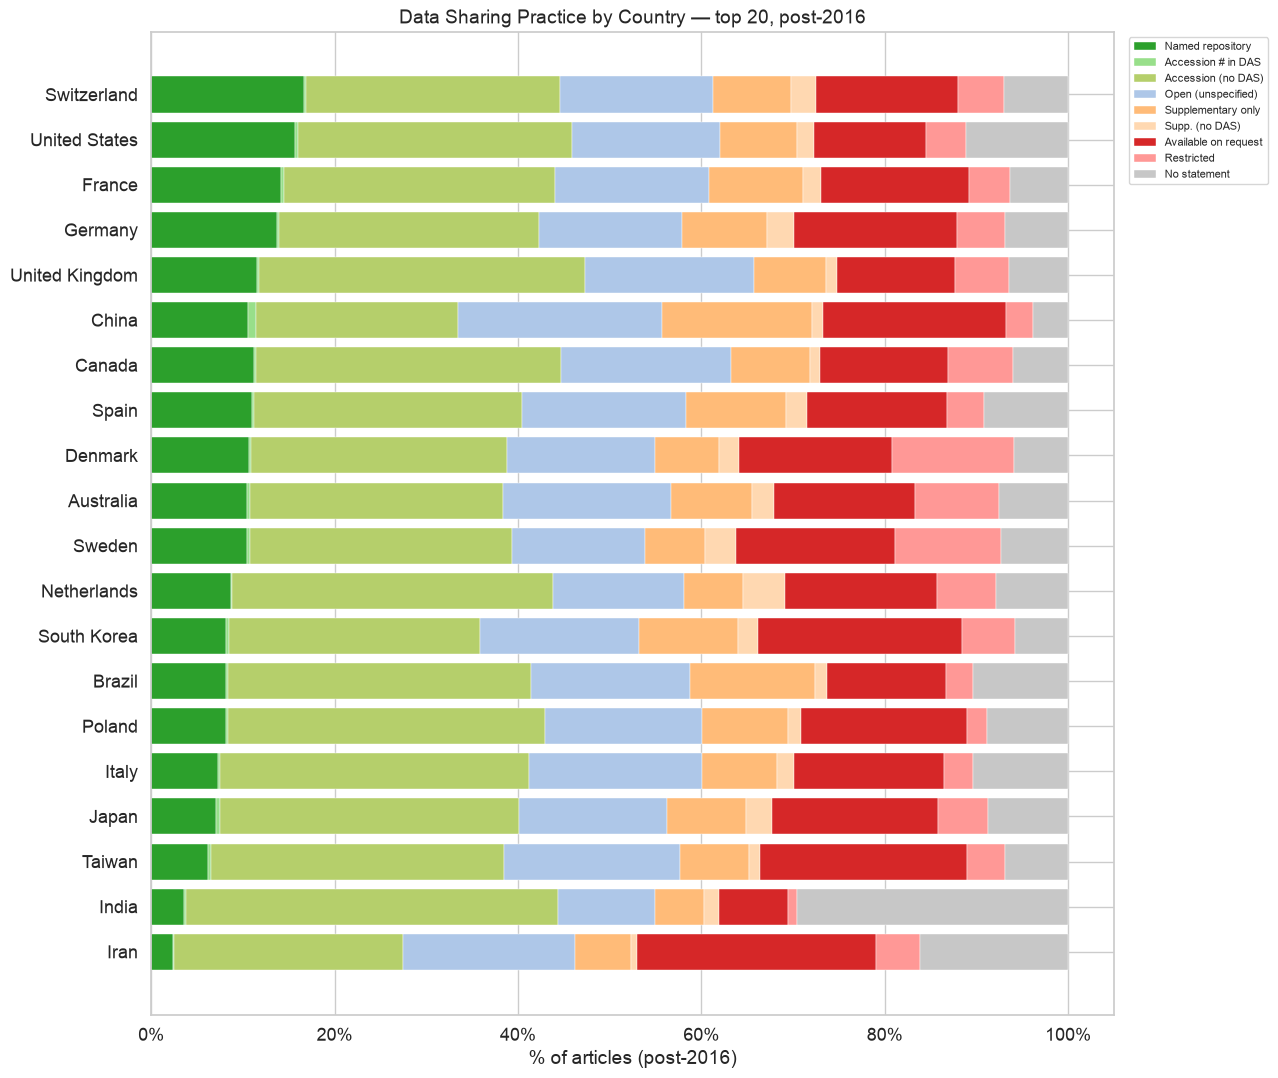

In [14]:
# ── 5.3  DAS category composition by country (top 20, post-2016 only) ───────
top20_iso = country_stats.head(20)["iso2"].tolist()
df_geo_cat = df_geo[df_geo["iso2"].isin(top20_iso) & (df_geo["year"] > 2016)].copy()

piv_gc = (df_geo_cat
          .groupby(["country","cat"])["article_id"]
          .count()
          .reset_index(name="n")
          .pivot_table(index="country", columns="cat", values="n", aggfunc="sum")
          .fillna(0))

piv_gc = piv_gc.reindex([c for c in CAT_ORDER if c in piv_gc.columns], axis=1)
piv_gc_pct = piv_gc.div(piv_gc.sum(axis=1), axis=0) * 100

# Sort by high-data-sharing-score share
pos_cols = [c for c in ["repository_named","accession_provided"] if c in piv_gc_pct.columns]
piv_gc_pct = piv_gc_pct.loc[
    piv_gc_pct[pos_cols].sum(axis=1).sort_values(ascending=True).index
]

fig, ax = plt.subplots(figsize=(FIG_W, max(5, len(piv_gc_pct) * 0.5 + 1)))
bot = np.zeros(len(piv_gc_pct))
for cat in piv_gc_pct.columns:
    ax.barh(piv_gc_pct.index, piv_gc_pct[cat], left=bot,
            color=CAT_COLOURS.get(cat,"#aaa"),
            label=CAT_LABELS.get(cat, cat),
            edgecolor="white", lw=0.3)
    bot += piv_gc_pct[cat].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("% of articles (post-2016)")
ax.set_title("Data Sharing Practice by Country — top 20, post-2016")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_11_country_categories.png", **SAVEFIG_KWARGS)
plt.show()


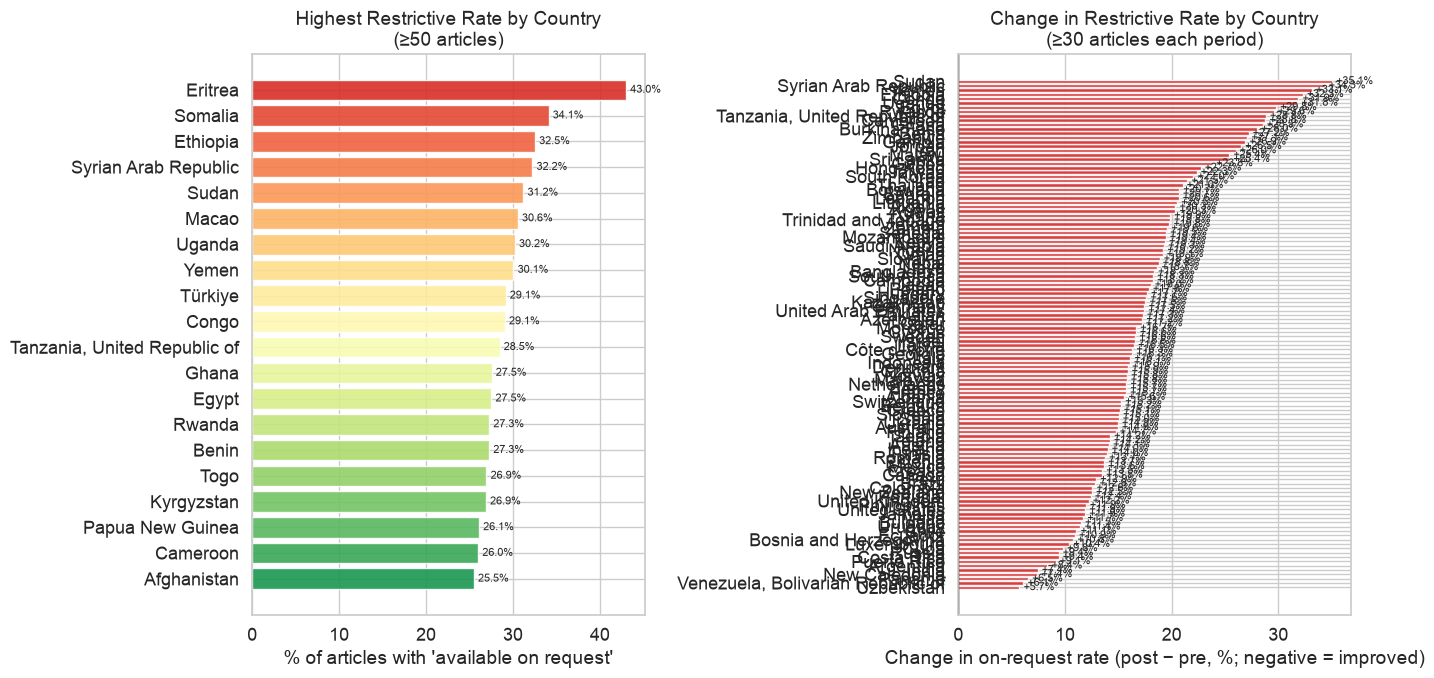

In [15]:
# ── 5.4  Restrictive-sharing spotlight: "available on request" rate by country ─────────
df_aor = (df_geo
          .assign(is_aor=df_geo["cat"] == "available_on_request")
          .groupby(["iso2","country"])
          .agg(n=("article_id","count"),
               n_aor=("is_aor","sum"))
          .reset_index())
df_aor["pct_aor"] = df_aor["n_aor"] / df_aor["n"] * 100
df_aor = df_aor[df_aor["n"] >= 50].sort_values("pct_aor", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 1, FIG_H + 2))

# Left: top 20 highest on-request rates
ax = axes[0]
top_aor = df_aor.head(20)
clrs_aor = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(top_aor)))
bars_aor = ax.barh(top_aor["country"][::-1], top_aor["pct_aor"][::-1],
                   color=clrs_aor, alpha=0.9, edgecolor="white")
ax.bar_label(bars_aor, fmt="{:.1f}%", padding=3, fontsize=8)
ax.set_xlabel("% of articles with 'available on request'")
ax.set_title("Highest Restrictive Rate by Country\n(≥50 articles)")

# Right: change in on-request rate pre→post for countries with data in both periods
df_aor_period = (df_geo[df_geo["year"] != 2016]
                 .assign(is_aor=df_geo["cat"] == "available_on_request")
                 .groupby(["iso2","country","period"])
                 .agg(n=("article_id","count"), n_aor=("is_aor","sum"))
                 .reset_index())
df_aor_period["pct"] = df_aor_period["n_aor"] / df_aor_period["n"] * 100

piv_aor = (df_aor_period
           .pivot_table(index=["iso2","country"], columns="period",
                        values="pct", aggfunc="mean")
           .reset_index())
piv_aor.columns.name = None
n_aor_piv = (df_aor_period
             .pivot_table(index=["iso2","country"], columns="period",
                          values="n", aggfunc="sum")
             .reset_index())
n_aor_piv.columns.name = None

mask_aor = ((n_aor_piv.get("pre_FAIR",  pd.Series(0, index=n_aor_piv.index)) >= 30) &
            (n_aor_piv.get("post_FAIR", pd.Series(0, index=n_aor_piv.index)) >= 30))
piv_aor = piv_aor[mask_aor.values].copy()

if "pre_FAIR" in piv_aor.columns and "post_FAIR" in piv_aor.columns:
    piv_aor["delta"] = piv_aor["post_FAIR"] - piv_aor["pre_FAIR"]
    piv_aor = piv_aor.sort_values("delta")

    ax = axes[1]
    clrs_chg = ["#2ca02c" if d < 0 else "#d62728" for d in piv_aor["delta"]]
    bars_chg = ax.barh(piv_aor["country"], piv_aor["delta"],
                       color=clrs_chg, alpha=0.85, edgecolor="white")
    ax.bar_label(bars_chg, fmt="{:+.1f}%", padding=3, fontsize=8)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Change in on-request rate (post − pre, %; negative = improved)")
    ax.set_title("Change in Restrictive Rate by Country\n(≥30 articles each period)")
else:
    axes[1].text(0.5, 0.5, "Insufficient data", ha="center", transform=axes[1].transAxes)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_12_country_aor.png", **SAVEFIG_KWARGS)
plt.show()


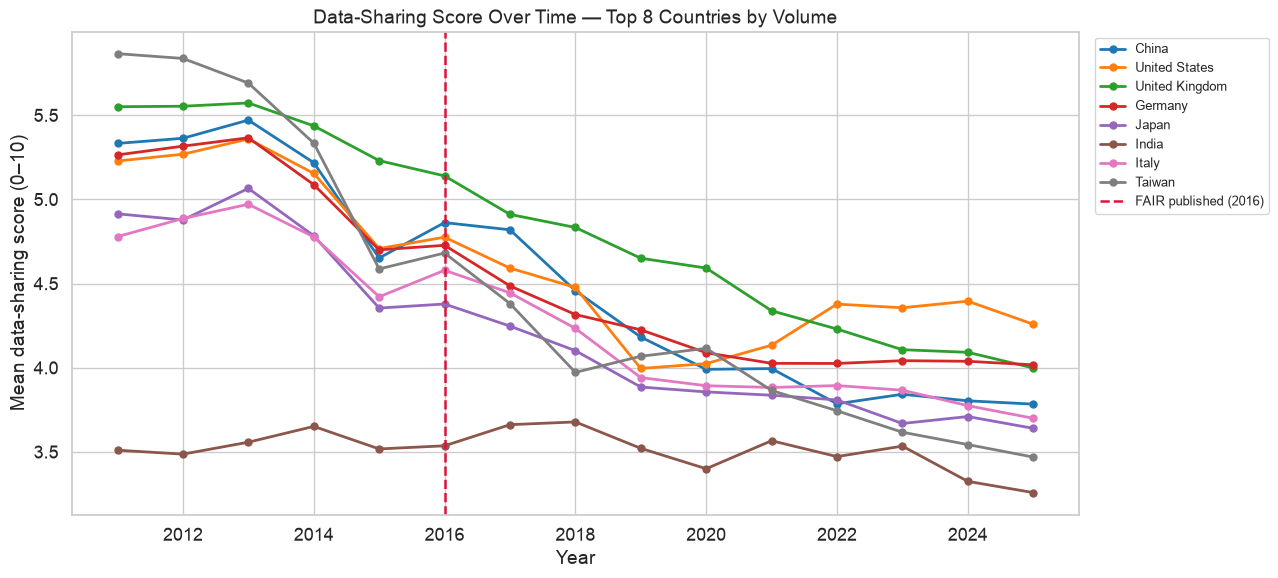

In [16]:
# ── 5.5  Data-sharing score trend over time for top 8 countries ─────────────────────
top8_iso = country_stats.head(8)["iso2"].tolist()
df_geo_yr = (df_geo[df_geo["iso2"].isin(top8_iso)]
             .groupby(["iso2","country","year"])
             .agg(avg_score=("data_sharing_score","mean"), n=("article_id","count"))
             .reset_index())
df_geo_yr = df_geo_yr[df_geo_yr["n"] >= 10]  # smooth out tiny-n years

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H + 1))
for i, iso in enumerate(top8_iso):
    grp = df_geo_yr[df_geo_yr["iso2"] == iso].sort_values("year")
    if grp.empty: continue
    name = grp["country"].iloc[0]
    ax.plot(grp["year"], grp["avg_score"],
            lw=2, marker="o", ms=5, color=PALETTE[i % 10], label=name)

ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published (2016)")
ax.set_xlabel("Year"); ax.set_ylabel("Mean data-sharing score (0–10)")
ax.set_title("Data-Sharing Score Over Time — Top 8 Countries by Volume")
ax.legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_13_country_trend.png", **SAVEFIG_KWARGS)
plt.show()


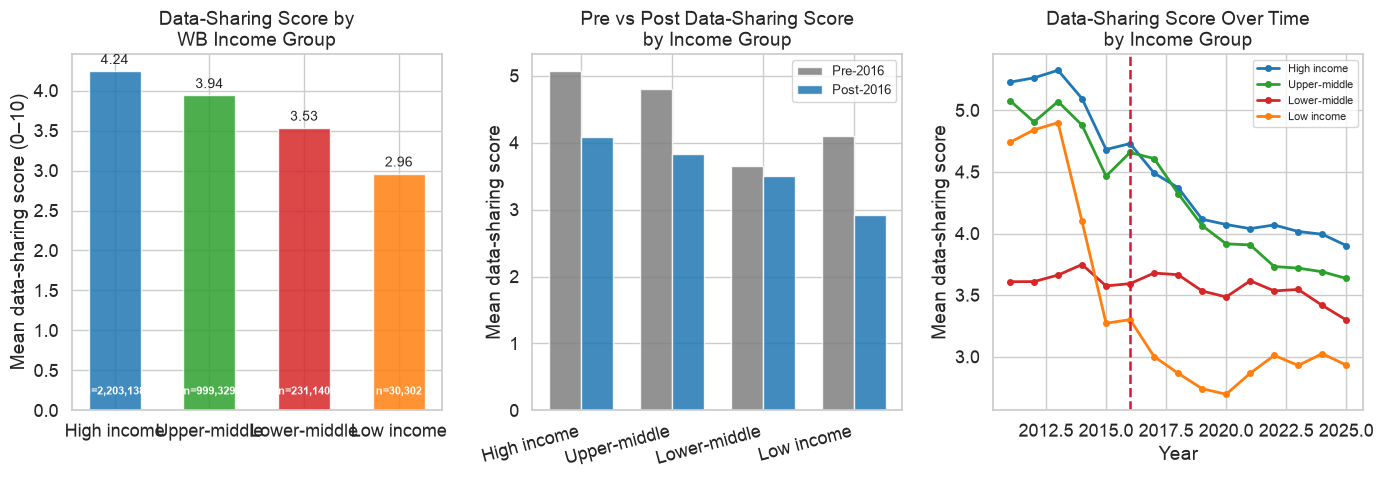

       label       n  avg_score  pre_score  post_score  delta
 High income 2203138      4.244      5.070       4.083 -0.987
Upper-middle  999329      3.942      4.804       3.836 -0.968
Lower-middle  231140      3.534      3.644       3.504 -0.140
  Low income   30302      2.962      4.094       2.913 -1.181


In [17]:
# ── 5.6  World Bank income group analysis ───────────────────────────────────
# Hardcoded WB 2023 income classifications for the most common countries
WB_INCOME = {
    # High income
    "US":"High","GB":"High","DE":"High","FR":"High","NL":"High","SE":"High",
    "CH":"High","AU":"High","CA":"High","JP":"High","KR":"High","DK":"High",
    "NO":"High","FI":"High","BE":"High","AT":"High","ES":"High","IT":"High",
    "PT":"High","IE":"High","NZ":"High","SG":"High","IL":"High","HK":"High",
    "TW":"High","CZ":"High","SK":"High","SI":"High","EE":"High","LT":"High",
    "LV":"High","HR":"High","HU":"High","PL":"High","CY":"High","MT":"High",
    "LU":"High","IS":"High","GR":"High","SA":"High","AE":"High","QA":"High",
    "KW":"High","BH":"High","OM":"High",
    # Upper middle income
    "CN":"UpperMid","BR":"UpperMid","ZA":"UpperMid","MX":"UpperMid",
    "TR":"UpperMid","RU":"UpperMid","TH":"UpperMid","MY":"UpperMid",
    "RO":"UpperMid","BG":"UpperMid","RS":"UpperMid","MK":"UpperMid",
    "BA":"UpperMid","AL":"UpperMid","IR":"UpperMid","IQ":"UpperMid",
    "JO":"UpperMid","LB":"UpperMid","LY":"UpperMid","TN":"UpperMid",
    "DZ":"UpperMid","MA":"UpperMid","EG":"UpperMid","PE":"UpperMid",
    "CO":"UpperMid","AR":"UpperMid","EC":"UpperMid","GT":"UpperMid",
    "CU":"UpperMid","AZ":"UpperMid","KZ":"UpperMid","AM":"UpperMid",
    # Lower middle income
    "IN":"LowerMid","PK":"LowerMid","NG":"LowerMid","BD":"LowerMid",
    "PH":"LowerMid","VN":"LowerMid","ID":"LowerMid","KE":"LowerMid",
    "GH":"LowerMid","TZ":"LowerMid","UZ":"LowerMid","UA":"LowerMid",
    "MM":"LowerMid","KH":"LowerMid","LA":"LowerMid","NP":"LowerMid",
    "SD":"LowerMid","SN":"LowerMid","CI":"LowerMid","CM":"LowerMid",
    # Low income
    "ET":"Low","CD":"Low","UG":"Low","MZ":"Low","MG":"Low","ML":"Low",
    "BF":"Low","NE":"Low","TD":"Low","SS":"Low","AF":"Low","MW":"Low",
    "GN":"Low","RW":"Low","SO":"Low","SL":"Low","LR":"Low","ZM":"Low",
}
INCOME_ORDER = ["High","UpperMid","LowerMid","Low"]
INCOME_LABELS = {
    "High": "High income", "UpperMid": "Upper-middle",
    "LowerMid": "Lower-middle", "Low": "Low income"
}

df_geo["income"] = df_geo["iso2"].map(WB_INCOME).fillna("Unknown")
df_geo_known = df_geo[df_geo["income"] != "Unknown"].copy()
df_geo_known["income_ord"] = pd.Categorical(
    df_geo_known["income"], categories=INCOME_ORDER, ordered=True)

ig_stats = (df_geo_known.groupby("income")
            .agg(n=("article_id","count"),
                 avg_score=("data_sharing_score","mean"),
                 pre_score=("data_sharing_score", lambda x:
                     x[df_geo_known.loc[x.index,"year"] < 2016].mean()),
                 post_score=("data_sharing_score", lambda x:
                     x[df_geo_known.loc[x.index,"year"] > 2016].mean()))
            .reindex(INCOME_ORDER).reset_index())
ig_stats["delta"] = ig_stats["post_score"] - ig_stats["pre_score"]
ig_stats["label"] = ig_stats["income"].map(INCOME_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 1, FIG_H))

# Panel A: mean data-sharing score by income group
ax = axes[0]
clrs_ig = [PALETTE[0], PALETTE[2], PALETTE[3], PALETTE[1]]
bars_ig = ax.bar(ig_stats["label"], ig_stats["avg_score"],
                 color=clrs_ig, alpha=0.85, edgecolor="white", width=0.55)
ax.bar_label(bars_ig, fmt="{:.2f}", padding=3, fontsize=10)
ax.set_ylabel("Mean data-sharing score (0–10)")
ax.set_title("Data-Sharing Score by\nWB Income Group")
for i, row in ig_stats.reset_index().iterrows():
    ax.text(i, 0.2, f"n={int(row['n']):,}", ha="center",
            fontsize=8, color="white", fontweight="bold")

# Panel B: pre/post grouped bars
ax = axes[1]
x_ig = np.arange(len(ig_stats)); w_ig = 0.35
ax.bar(x_ig - w_ig/2, ig_stats["pre_score"],  w_ig, label="Pre-2016",
       color=PALETTE[7], alpha=0.85, edgecolor="white")
ax.bar(x_ig + w_ig/2, ig_stats["post_score"], w_ig, label="Post-2016",
       color=PALETTE[0], alpha=0.85, edgecolor="white")
ax.set_xticks(x_ig); ax.set_xticklabels(ig_stats["label"], rotation=15, ha="right")
ax.set_ylabel("Mean data-sharing score"); ax.legend(fontsize=9)
ax.set_title("Pre vs Post Data-Sharing Score\nby Income Group")

# Panel C: income group score over time
ax = axes[2]
for i, ig in enumerate(INCOME_ORDER):
    grp = (df_geo_known[df_geo_known["income"] == ig]
           .groupby("year")["data_sharing_score"].mean().reset_index())
    ax.plot(grp["year"], grp["data_sharing_score"], lw=2, marker="o", ms=4,
            color=clrs_ig[i], label=INCOME_LABELS[ig])
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--")
ax.set_xlabel("Year"); ax.set_ylabel("Mean data-sharing score")
ax.set_title("Data-Sharing Score Over Time\nby Income Group")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_14_income_group.png", **SAVEFIG_KWARGS)
plt.show()
print(ig_stats[["label","n","avg_score","pre_score","post_score","delta"]].round(3).to_string(index=False))


International articles : n=1,024,929  mean=4.394
Domestic articles      : n=2,579,732  mean=3.971
Mann-Whitney (intl > domestic): U=1445373225564  p=0.000e+00


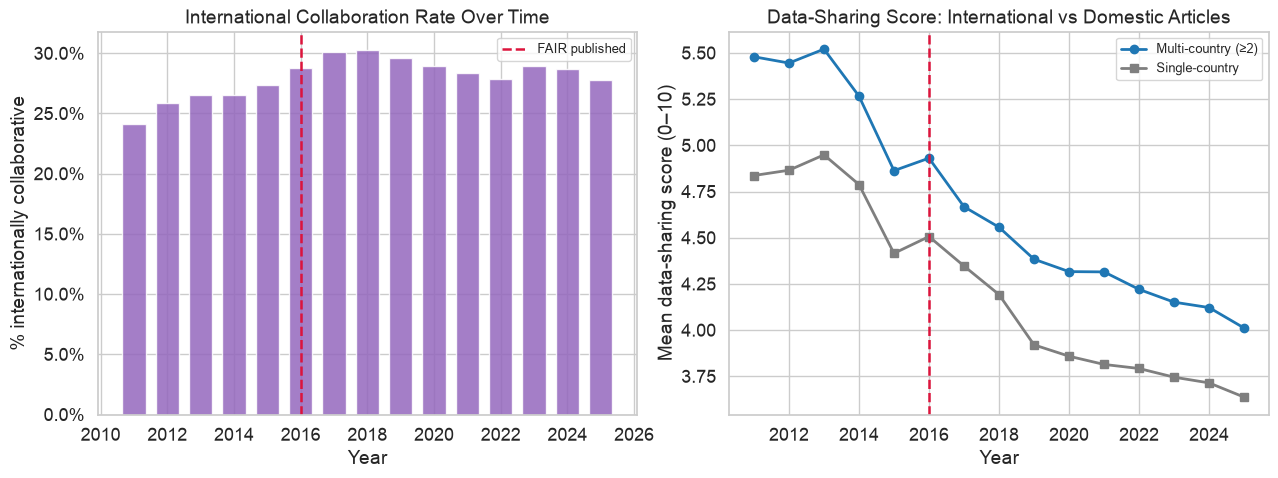

In [18]:
# ── 5.7  International collaboration: multi-country articles ─────────────────
# An article is "internationally collaborative" if its authors span ≥2 countries.
df_collab_raw = qdb("""
    SELECT
        a.article_id,
        a.year AS year,
        dc.data_sharing_score,
        af_tbl.affiliation      AS aff_text
    FROM article           a
    JOIN das_category      dc   ON dc.article_id  = a.article_id
    JOIN article_author    aa   ON aa.article_id  = a.article_id
    JOIN author_affiliation aaf ON aaf.article_id  = a.article_id
                                AND aaf.author_id   = aa.author_id
    JOIN affiliation        af_tbl ON af_tbl.affiliation_id = aaf.affiliation_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

df_collab_raw["iso2"] = df_collab_raw["aff_text"].apply(_country_from_affil)
df_collab_raw = df_collab_raw.dropna(subset=["iso2"])

# Count distinct countries per article
article_countries = (df_collab_raw.groupby("article_id")["iso2"]
                     .nunique().reset_index(name="n_countries"))
article_meta = df_collab_raw.drop_duplicates("article_id")[
    ["article_id","year","data_sharing_score"]]
df_collab = article_meta.merge(article_countries, on="article_id")
df_collab["is_intl"] = df_collab["n_countries"] >= 2

# Proportion of internationally collaborative articles by year
collab_yr = (df_collab.groupby("year")
             .agg(n                = ("article_id", "count"),
                  n_intl           = ("is_intl",    "sum"),
                  avg_score_single = ("data_sharing_score",
                      lambda x: x[~df_collab.loc[x.index, "is_intl"]].mean()),
                  avg_score_intl   = ("data_sharing_score",
                      lambda x: x[df_collab.loc[x.index,  "is_intl"]].mean()))
             .reset_index())
collab_yr["pct_intl"] = collab_yr["n_intl"] / collab_yr["n"] * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
ax.bar(collab_yr["year"], collab_yr["pct_intl"],
       color=PALETTE[4], alpha=0.85, edgecolor="white", width=0.7)
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Year"); ax.set_ylabel("% internationally collaborative")
ax.set_title("International Collaboration Rate Over Time")
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(collab_yr["year"], collab_yr["avg_score_intl"],
        lw=2, marker="o", color=PALETTE[0], label="Multi-country (\u22652)")
ax.plot(collab_yr["year"], collab_yr["avg_score_single"],
        lw=2, marker="s", color=PALETTE[7], label="Single-country")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--")
ax.set_xlabel("Year"); ax.set_ylabel("Mean data-sharing score (0–10)")
ax.set_title("Data-Sharing Score: International vs Domestic Articles")
ax.legend(fontsize=9)

# Statistical test: do internationally collaborative articles score higher?
intl_scores   = df_collab[df_collab["is_intl"]]["data_sharing_score"]
single_scores = df_collab[~df_collab["is_intl"]]["data_sharing_score"]
u_stat, p_val = stats.mannwhitneyu(intl_scores, single_scores, alternative="greater")
print(f"International articles : n={len(intl_scores):,}  mean={intl_scores.mean():.3f}")
print(f"Domestic articles      : n={len(single_scores):,}  mean={single_scores.mean():.3f}")
print(f"Mann-Whitney (intl > domestic): U={u_stat:.0f}  p={p_val:.3e}")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_geo_15_collaboration.png", **SAVEFIG_KWARGS)
plt.show()


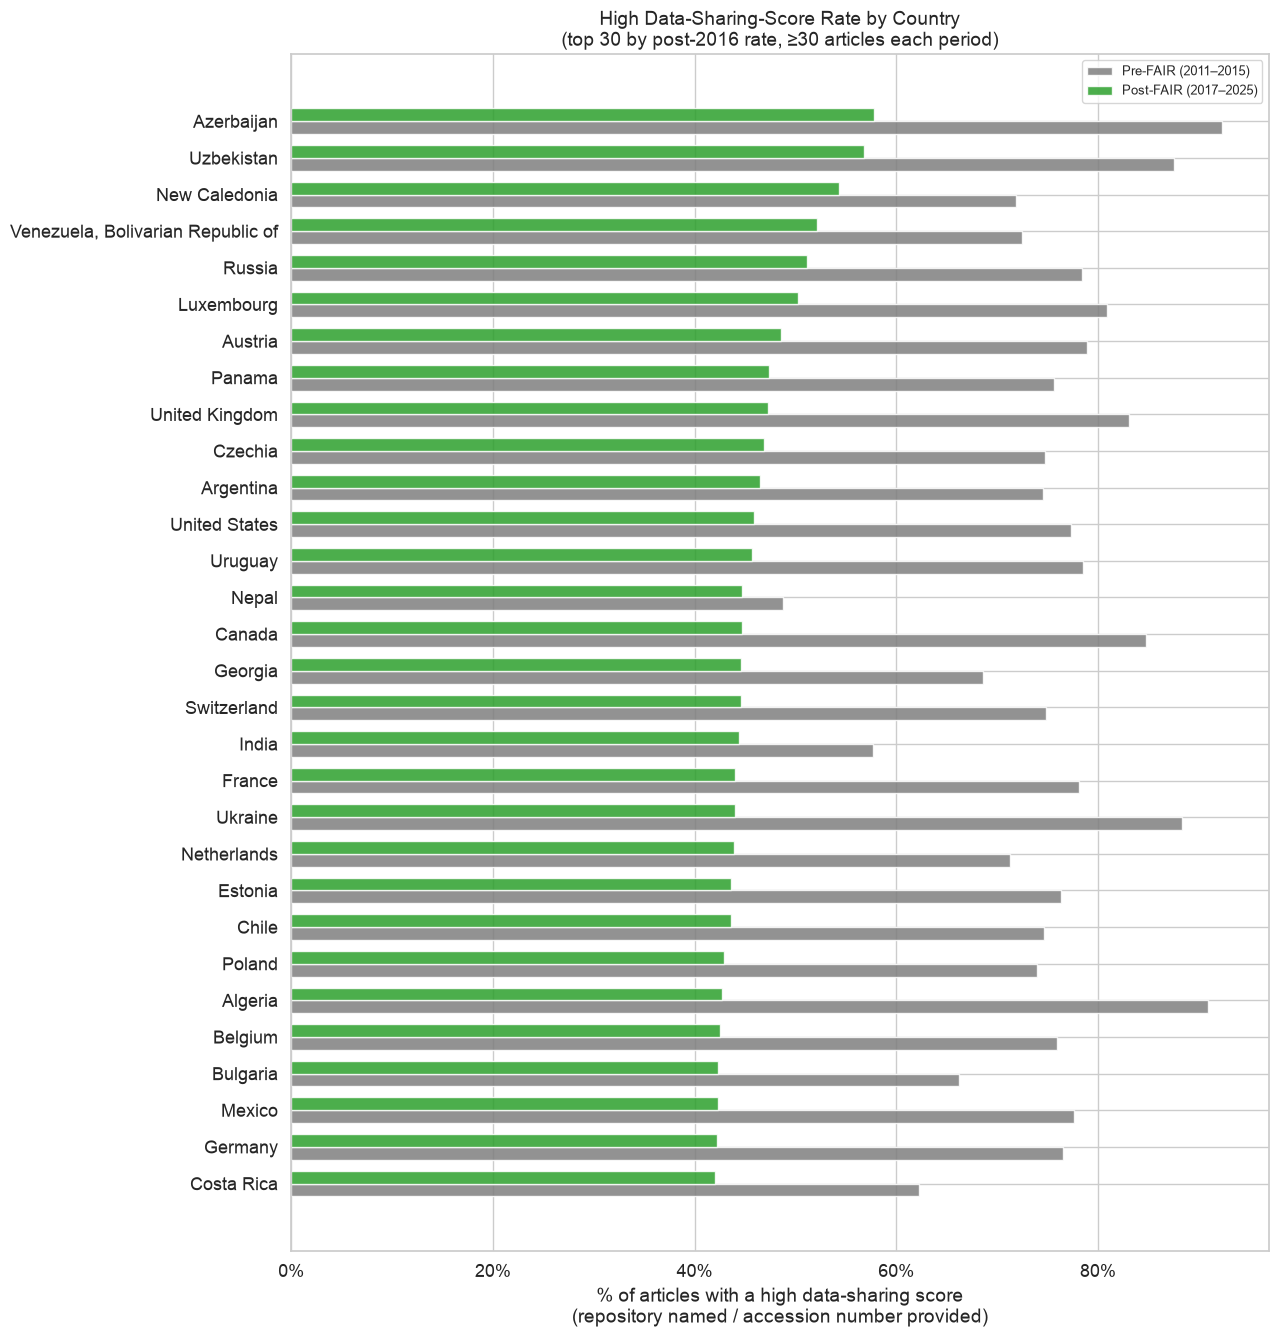

Top 10 countries by high-data-sharing-score rate improvement:
                          country  pre_FAIR  post_FAIR  delta
                            Nepal     48.79      44.70  -4.09
                            India     57.71      44.37 -13.33
                    New Caledonia     71.88      54.32 -17.55
                       Costa Rica     62.26      42.02 -20.25
Venezuela, Bolivarian Republic of     72.48      52.11 -20.36
                         Bulgaria     66.23      42.34 -23.89
                          Georgia     68.60      44.61 -24.00
                           Russia     78.39      51.10 -27.29
                      Netherlands     71.29      43.87 -27.42
                          Czechia     74.70      46.87 -27.83


In [19]:
# ── 5.8  Global shifts: each country's share of high-data-sharing-score output ─────────
# "high data-sharing score" = repository_named or accession_provided
SHARE_POS = {"repository_named","accession_provided","no_das_but_accession"}

df_geo["share_pos"] = df_geo["cat"].isin(SHARE_POS)

share_stats = (df_geo[df_geo["year"] != 2016]
               .groupby(["iso2","country","period"])
               .agg(n=("article_id","count"),
                    n_pos=("share_pos","sum"))
               .reset_index())
share_stats["pct_pos"] = share_stats["n_pos"] / share_stats["n"] * 100

piv_share = (share_stats
             .pivot_table(index=["iso2","country"], columns="period",
                          values="pct_pos", aggfunc="mean")
             .reset_index())
piv_share.columns.name = None

n_share = (share_stats
           .pivot_table(index=["iso2","country"], columns="period",
                        values="n", aggfunc="sum")
           .reset_index())
n_share.columns.name = None
mask_sh = ((n_share.get("pre_FAIR",  pd.Series(0, index=n_share.index)) >= 30) &
           (n_share.get("post_FAIR", pd.Series(0, index=n_share.index)) >= 30))
piv_share = piv_share[mask_sh.values].copy()

if "pre_FAIR" in piv_share.columns and "post_FAIR" in piv_share.columns:
    piv_share["delta"] = piv_share["post_FAIR"] - piv_share["pre_FAIR"]
    piv_share = piv_share.sort_values("post_FAIR", ascending=False).head(30)

    fig, ax = plt.subplots(figsize=(FIG_W, max(5, len(piv_share) * 0.42 + 1)))
    y  = np.arange(len(piv_share)); w = 0.35
    ax.barh(y - w/2, piv_share["pre_FAIR"][::-1],  w,
            color=PALETTE[7], alpha=0.85, label="Pre-FAIR (2011–2015)",
            edgecolor="white")
    ax.barh(y + w/2, piv_share["post_FAIR"][::-1], w,
            color="#2ca02c", alpha=0.85, label="Post-FAIR (2017–2025)",
            edgecolor="white")
    ax.set_yticks(y)
    ax.set_yticklabels(piv_share["country"][::-1])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel("% of articles with a high data-sharing score\n"
                  "(repository named / accession number provided)")
    ax.set_title("High Data-Sharing-Score Rate by Country\n"
                 "(top 30 by post-2016 rate, ≥30 articles each period)")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_geo_16_country_fairpos.png", **SAVEFIG_KWARGS)
    plt.show()

    # Top improvers
    top_imp_geo = piv_share.nlargest(10, "delta")[["country","pre_FAIR","post_FAIR","delta"]]
    print("Top 10 countries by high-data-sharing-score rate improvement:")
    print(top_imp_geo.round(2).to_string(index=False))


---
## 6 · Key Findings & Discussion

### Discipline, OA status, and research-area patterns (2011-2025)

1. **Discipline gap is wide and largely stable.** `genomics` leads at a mean data-sharing score
   of 5.33 (n=15,934), while `public_health` trails at 3.96 -- a gap driven by genomics'
   decades-old norm of inline accession-number sharing (GEO/SRA) predating the FAIR paper
   itself. `bioinformatics` shows the largest pre/post-2016 improvement of any discipline
   (+0.94), consistent with a field that adopted DAS mandates enthusiastically once they arrived.

2. **Gold OA scores highest overall but *declined* after 2016 (-0.17), while subscription
   journals improved (+0.21).** This is counter-intuitive if "open access culture = FAIR
   culture" were the whole story -- more likely, subscription journals (the majority of the
   corpus) were starting from a lower base and had more room to close the gap once major
   publishers imposed DAS mandates on all their journals regardless of OA status, while gold OA
   venues' early-adopter advantage eroded as the rest of the corpus caught up.

3. **Broad MeSH research areas confirm the discipline pattern**: `bioinformatics` (+0.92) and
   `structural_biology` (+0.63) improved the most from pre- to post-FAIR; `ecology` is the only
   broad area that got *worse* (-0.10).

### Geographical patterns (this notebook's core contribution)

- Country-level data-sharing adoption, restrictive-sharing ("available on request") rates, World Bank
  income-group comparisons, and international-collaboration effects are covered in §5 above --
  see the printed country tables and `country_stats.csv` / `income_group_scores.csv` in the
  exports below for the full numbers.

### Limitations

- Country is inferred from **first-author affiliation text only** -- a simple regex/lookup
  match against country names and common aliases, not a validated geocoding service. Messy or
  non-standard affiliation strings resolve to no country and are excluded (§5.0 prints the
  resolution rate).
- The discipline/OA-status/MeSH breakdowns here are single-variable cuts; §4's funder ×
  discipline and funder × OA heatmaps are the only cross-tabulations, so three-way interactions
  (e.g. funder × discipline × country) aren't tested.
- As elsewhere in this project, the data-sharing score is a Stage-4 heuristic, not a formal
  FAIR assessment.

### What this notebook does *not* cover (see instead)

This notebook used to duplicate the corpus-wide overview, publisher-level funder league table,
and per-author productivity trajectory analyses that are already covered elsewhere -- those
sections were removed rather than kept as a second copy:
- Corpus-wide article counts, DAS category trend, data-sharing score trend, repository landscape,
  accession numbers, secondary signals, F-UJI results, before/after statistics ->
  `01_corpus_overview.ipynb`
- Top-funder league table (volume, mean score, pre/post delta, on-request rate) ->
  `08_mandate_compliance.ipynb`
- Per-author pre/post data-sharing score trajectories by productivity tier ->
  `06_gender_analysis.ipynb` (there, split by inferred first-author gender)

---
## 7 · Export Summary Tables

Export the tables this notebook actually computes -- discipline, OA status, MeSH, funder
cross-tabs, and the full geographic analysis -- to CSV.

In [20]:
export_dir = Path("../results/fair_geographical_exports")
export_dir.mkdir(parents=True, exist_ok=True)

exports = {}

# Discipline (§1)
if HAS_DISC:
    exports["discipline_fair_scores.csv"] = df_disc
    if "piv_dc_pct" in dir():
        exports["discipline_das_category_mix.csv"] = piv_dc_pct.reset_index()

# OA status (§2)
if HAS_OA:
    exports["oa_status_fair_scores.csv"] = df_oa
    exports["oa_status_fair_trend.csv"]  = df_oa_yr

# MeSH (§3)
if HAS_MESH:
    exports["mesh_top_bottom_terms.csv"] = pd.concat(
        [df_mesh_top.assign(rank="top"), df_mesh_bot.assign(rank="bottom")])
    exports["mesh_broad_area_pre_post.csv"] = piv_broad.reset_index()

# Funder cross-tabs (§4)
if HAS_FUNDER and HAS_DISC:
    exports["funder_discipline_heatmap.csv"] = df_fd
if HAS_FUNDER and HAS_OA:
    exports["funder_oa_heatmap.csv"] = df_foa

# Geographical (§5)
exports["country_stats.csv"] = country_stats
if "piv_cp" in dir():
    exports["country_period_scores.csv"] = piv_cp
exports["country_category_mix.csv"] = piv_gc_pct.reset_index()
exports["country_available_on_request.csv"] = df_aor
exports["income_group_scores.csv"] = ig_stats
exports["collaboration_by_year.csv"] = collab_yr
if "piv_share" in dir():
    exports["country_fair_positive_share.csv"] = piv_share

for fname, out_df in exports.items():
    p = export_dir / fname
    out_df.to_csv(p, index=False)
    print(f"  ✅ {p}  ({len(out_df):,} rows × {len(out_df.columns)} cols)")

print(f"\nAll exports saved to ./{export_dir}/")

  ✅ ../results/fair_geographical_exports/discipline_fair_scores.csv  (13 rows × 6 cols)
  ✅ ../results/fair_geographical_exports/discipline_das_category_mix.csv  (13 rows × 10 cols)
  ✅ ../results/fair_geographical_exports/oa_status_fair_scores.csv  (4 rows × 6 cols)
  ✅ ../results/fair_geographical_exports/oa_status_fair_trend.csv  (60 rows × 4 cols)
  ✅ ../results/fair_geographical_exports/mesh_top_bottom_terms.csv  (40 rows × 4 cols)
  ✅ ../results/fair_geographical_exports/mesh_broad_area_pre_post.csv  (13 rows × 4 cols)
  ✅ ../results/fair_geographical_exports/funder_discipline_heatmap.csv  (38,364 rows × 4 cols)
  ✅ ../results/fair_geographical_exports/funder_oa_heatmap.csv  (37,901 rows × 4 cols)
  ✅ ../results/fair_geographical_exports/country_stats.csv  (219 rows × 7 cols)
  ✅ ../results/fair_geographical_exports/country_period_scores.csv  (100 rows × 5 cols)
  ✅ ../results/fair_geographical_exports/country_category_mix.csv  (20 rows × 10 cols)
  ✅ ../results/fair_geographical

In [21]:
con.close()
print("Database connection closed.")
print("\nFigures saved:")
for fig_file in sorted(FIGURES_DIR.glob("fig_geo_*.png")):
    print(f"  {fig_file}")


Database connection closed.

Figures saved:
  ../figures/fig_geo_01_discipline_scores.png
  ../figures/fig_geo_02_discipline_heatmap.png
  ../figures/fig_geo_03_oa_scores.png
  ../figures/fig_geo_04_oa_trend.png
  ../figures/fig_geo_05_mesh_scores.png
  ../figures/fig_geo_06_mesh_broad.png
  ../figures/fig_geo_07_funder_discipline.png
  ../figures/fig_geo_08_funder_oa.png
  ../figures/fig_geo_09_country_volume_score.png
  ../figures/fig_geo_10_country_delta.png
  ../figures/fig_geo_11_country_categories.png
  ../figures/fig_geo_12_country_aor.png
  ../figures/fig_geo_13_country_trend.png
  ../figures/fig_geo_14_income_group.png
  ../figures/fig_geo_15_collaboration.png
  ../figures/fig_geo_16_country_fairpos.png
